
# Task 1: Introduction, Pipelines and Tokenizer

## Objective
Understand the basic concepts of Transformers, use a pretrained sentiment analysis model, explore tokenization and padding, and inspect the architecture and parameters of DistilBERT.

## Expected Output
- Sentiment predictions for five sentences
- Transformer history timeline
- Impact and disadvantages of Transformers
- Tokenizer output, input IDs and attention masks
- Padded sentence batch
- Model configuration and parameter information


## Import libraries and set random seeds

In [1]:

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns

from transformers import (
    pipeline,
    AutoTokenizer,
    AutoModel,
    AutoModelForSequenceClassification
)

# Reproducibility
torch.manual_seed(42)
np.random.seed(42)

# Plot settings
sns.set_theme(style="whitegrid")

print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

print("\nLibraries imported successfully.")


NumPy version: 2.4.6
Pandas version: 3.0.6
PyTorch version: 2.14.0+cpu
CUDA available: False

Libraries imported successfully.


## Task 1.1 — Install and use the first sentiment pipeline


## 1.1 First Hugging Face Pipeline

A Transformer is a neural network architecture that uses attention mechanisms to understand relationships between tokens. A Hugging Face pipeline provides a simple interface for running pretrained models. In sentiment analysis, the model predicts whether a sentence expresses positive or negative sentiment. A pipeline handles tokenization, the model forward pass and post-processing automatically.


## Run sentiment analysis on five sentences

In [2]:

model_name = "distilbert-base-uncased-finetuned-sst-2-english"

sentiment_pipeline = pipeline(
    "sentiment-analysis",
    model=model_name,
    device=-1
)

sentences = [
    "I absolutely love learning deep learning.",
    "This movie was boring and disappointing.",
    "The food was excellent and delicious.",
    "I do not think this product is good.",
    "The movie was not bad, and I enjoyed it."
]

results = sentiment_pipeline(sentences)

for i, (sentence, result) in enumerate(
    zip(sentences, results), start=1
):
    print(f"Sentence {i}: {sentence}")
    print("Predicted label:", result["label"])
    print("Confidence score:", round(result["score"], 4))
    print("-" * 70)


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Sentence 1: I absolutely love learning deep learning.
Predicted label: POSITIVE
Confidence score: 0.9998
----------------------------------------------------------------------
Sentence 2: This movie was boring and disappointing.
Predicted label: NEGATIVE
Confidence score: 0.9998
----------------------------------------------------------------------
Sentence 3: The food was excellent and delicious.
Predicted label: POSITIVE
Confidence score: 0.9999
----------------------------------------------------------------------
Sentence 4: I do not think this product is good.
Predicted label: NEGATIVE
Confidence score: 0.9998
----------------------------------------------------------------------
Sentence 5: The movie was not bad, and I enjoyed it.
Predicted label: POSITIVE
Confidence score: 0.9999
----------------------------------------------------------------------



### How does a pipeline work?

A sentiment analysis pipeline hides three main steps:

1. Tokenization: converts text into tokens and numerical input IDs.
2. Model forward pass: passes the IDs through the pretrained Transformer to obtain prediction scores.
3. Post-processing: converts the model outputs into readable labels and confidence scores.

This makes it easier to use a pretrained model without manually implementing each step.


## Task 1.2 — Transformer history


## 1.2 Introduction and History of Transformers

Transformers became important because they can process token representations in parallel and learn relationships between distant words using attention. Earlier RNNs and LSTMs process sequences step by step, which can make training slower. They can also struggle to preserve information across long sequences. Transformers reduce these limitations, although attention can be computationally expensive for long inputs.


## Create the timeline table

In [3]:

history = pd.DataFrame({
    "Year": [
        "2014–2015",
        "2017",
        "2018",
        "2019",
        "2020 and later"
    ],
    "Model or Paper": [
        "Bahdanau / Luong Attention",
        "Attention Is All You Need",
        "BERT and GPT",
        "GPT-2, T5 and DistilBERT",
        "Large language models and Vision Transformers"
    ],
    "Why It Mattered": [
        "Attention helped sequence-to-sequence models focus on relevant encoder states.",
        "Introduced the Transformer architecture based on attention rather than recurrent layers.",
        "BERT popularized bidirectional encoder representations; GPT developed autoregressive generation.",
        "GPT-2 demonstrated stronger text generation, T5 unified text tasks, and DistilBERT offered a smaller model.",
        "Transformers expanded into chat assistants, code generation, multimodal AI and image understanding."
    ]
})

display(history)


,Year,Model or Paper,Why It Mattered
0,2014–2015,Bahdanau / Luong Attention,Attention helped sequence-to-sequence models f...
1,2017,Attention Is All You Need,Introduced the Transformer architecture based ...
2,2018,BERT and GPT,BERT popularized bidirectional encoder represe...
3,2019,"GPT-2, T5 and DistilBERT","GPT-2 demonstrated stronger text generation, T..."
4,2020 and later,Large language models and Vision Transformers,"Transformers expanded into chat assistants, co..."



### Why did Transformers replace many RNN and LSTM workflows?

RNNs and LSTMs process tokens sequentially, limiting parallel processing during training. Although LSTMs help preserve information over longer sequences, learning distant relationships can still be difficult. Transformers use self-attention to connect tokens directly and process the sequence in parallel during training. However, standard self-attention requires memory and computation that grow approximately quadratically with sequence length.


## Task 1.3 — Impact and disadvantages


## 1.3 Impact and Disadvantages of Transformers

### Impact
- Machine translation
- Search engines and information retrieval
- Chat assistants and question answering
- Code completion and code generation
- Image understanding and generation
- Protein structure prediction

### Disadvantages
- Standard full self-attention has quadratic cost in sequence length.
- Models have context-window limits.
- Large models can require substantial memory and computing resources.
- Training powerful models can require large datasets.
- Generative models can produce hallucinations or incorrect facts.
- Their internal behaviour can be difficult to interpret.


## Task 1.4 — Tokenizer in action

## Load the tokenizer

In [4]:

tokenizer = AutoTokenizer.from_pretrained(model_name)

text = "Transformers are surprisingly easy to understand."

tokens = tokenizer.tokenize(text)
encoded = tokenizer(
    text,
    return_tensors="pt"
)

print("Original text:")
print(text)

print("\nTokens:")
print(tokens)

print("\nInput IDs:")
print(encoded["input_ids"])

print("\nAttention mask:")
print(encoded["attention_mask"])

print("\nDecoded text:")
print(tokenizer.decode(encoded["input_ids"][0]))


Original text:
Transformers are surprisingly easy to understand.

Tokens:
['transformers', 'are', 'surprisingly', 'easy', 'to', 'understand', '.']

Input IDs:
tensor([[  101, 19081,  2024, 10889,  3733,  2000,  3305,  1012,   102]])

Attention mask:
tensor([[1, 1, 1, 1, 1, 1, 1, 1, 1]])

Decoded text:
[CLS] transformers are surprisingly easy to understand. [SEP]


## Demonstrate subword tokenization

In [5]:

rare_word = "antidisestablishmentarianism"

print("Original word:", rare_word)
print("Subword tokens:", tokenizer.tokenize(rare_word))

rare_encoded = tokenizer(rare_word)

print("Input IDs:", rare_encoded["input_ids"])
print("Decoded tokens:", tokenizer.convert_ids_to_tokens(
    rare_encoded["input_ids"]
))


Original word: antidisestablishmentarianism
Subword tokens: ['anti', '##dis', '##est', '##ab', '##lish', '##ment', '##arian', '##ism']
Input IDs: [101, 3424, 10521, 4355, 7875, 13602, 3672, 12199, 2964, 102]
Decoded tokens: ['[CLS]', 'anti', '##dis', '##est', '##ab', '##lish', '##ment', '##arian', '##ism', '[SEP]']



### What are special tokens and subwords?

`[CLS]` is a special classification token used at the beginning of a DistilBERT sequence. `[SEP]` marks a sequence boundary and can separate text segments. The tokenizer may also add other special tokens depending on the model. Subword tokenization allows a model to represent uncommon words and parts of words without needing a separate vocabulary entry for every possible word.


## Task 1.5 — Batching and padding
## Tokenize two sentences of different lengths

In [6]:

sentences_batch = [
    "Transformers learn relationships between tokens.",
    "Deep learning models use attention."
]

batch = tokenizer(
    sentences_batch,
    padding=True,
    return_tensors="pt"
)

print("Input IDs:")
print(batch["input_ids"])

print("\nAttention mask:")
print(batch["attention_mask"])

print("\nDecoded batch:")
for ids in batch["input_ids"]:
    print(tokenizer.decode(ids))

print("\nBatch shape:", tuple(batch["input_ids"].shape))


Input IDs:
tensor([[  101, 19081,  4553,  6550,  2090, 19204,  2015,  1012,   102],
        [  101,  2784,  4083,  4275,  2224,  3086,  1012,   102,     0]])

Attention mask:
tensor([[1, 1, 1, 1, 1, 1, 1, 1, 1],
        [1, 1, 1, 1, 1, 1, 1, 1, 0]])

Decoded batch:
[CLS] transformers learn relationships between tokens. [SEP]
[CLS] deep learning models use attention. [SEP] [PAD]

Batch shape: (2, 9)



### Why is padding needed?

Sentences often contain different numbers of tokens, but batched tensor operations require consistent dimensions. Padding adds placeholder tokens to shorter sequences. The attention mask identifies real tokens and padding positions so the model can avoid attending to padding as meaningful content. We will inspect this behaviour more closely in Task 4.


## Task 1.6 — Model anatomy at a glance
## Load DistilBERT and inspect its configuration

In [7]:

classification_model = AutoModelForSequenceClassification.from_pretrained(
    model_name
)

classification_model.eval()

config = classification_model.config

print("Model ID:", model_name)
print("\nModel configuration:")
print(config)

print("\nKey architecture values:")
print("Number of layers:", config.n_layers)
print("Number of attention heads:", config.n_heads)
print("Hidden size:", config.dim)
print("Vocabulary size:", config.vocab_size)
print("Maximum position embeddings:", config.max_position_embeddings)

total_parameters = sum(
    parameter.numel()
    for parameter in classification_model.parameters()
)

trainable_parameters = sum(
    parameter.numel()
    for parameter in classification_model.parameters()
    if parameter.requires_grad
)




Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Model ID: distilbert-base-uncased-finetuned-sst-2-english

Model configuration:
DistilBertConfig {
  "activation": "gelu",
  "architectures": [
    "DistilBertForSequenceClassification"
  ],
  "attention_dropout": 0.1,
  "bos_token_id": null,
  "dim": 768,
  "dropout": 0.1,
  "dtype": "float32",
  "eos_token_id": null,
  "finetuning_task": "sst-2",
  "hidden_dim": 3072,
  "id2label": {
    "0": "NEGATIVE",
    "1": "POSITIVE"
  },
  "initializer_range": 0.02,
  "label2id": {
    "NEGATIVE": 0,
    "POSITIVE": 1
  },
  "max_position_embeddings": 512,
  "model_type": "distilbert",
  "n_heads": 12,
  "n_layers": 6,
  "output_past": true,
  "pad_token_id": 0,
  "qa_dropout": 0.1,
  "seq_classif_dropout": 0.2,
  "sinusoidal_pos_embds": false,
  "tie_weights_": true,
  "tie_word_embeddings": true,
  "transformers_version": "5.20.2",
  "vocab_size": 30522
}


Key architecture values:
Number of layers: 6
Number of attention heads: 12
Hidden size: 768
Vocabulary size: 30522
Maximum position emb

In [8]:
print("\nTotal parameters:", f"{total_parameters:,}")
print("Trainable parameters:", f"{trainable_parameters:,}")


Total parameters: 66,955,010
Trainable parameters: 66,955,010


## Create the architecture summary table

In [9]:

architecture_summary = pd.DataFrame({
    "Property": [
        "Model ID",
        "Architecture",
        "Number of Transformer layers",
        "Attention heads per layer",
        "Hidden size",
        "Vocabulary size",
        "Maximum position embeddings",
        "Total parameters"
    ],
    "Value": [
        model_name,
        "DistilBERT sequence classification",
        config.n_layers,
        config.n_heads,
        config.dim,
        config.vocab_size,
        config.max_position_embeddings,
        f"{total_parameters:,}"
    ]
})

display(architecture_summary)


,Property,Value
0,Model ID,distilbert-base-uncased-finetuned-sst-2-english
1,Architecture,DistilBERT sequence classification
2,Number of Transformer layers,6
3,Attention heads per layer,12
4,Hidden size,768
5,Vocabulary size,30522
6,Maximum position embeddings,512
7,Total parameters,"66,955,010"


## Print the first 15 parameter names

In [10]:

print("First 15 model parameter names:\n")

for index, (name, parameter) in enumerate(
    classification_model.named_parameters()
):
    if index >= 15:
        break

    print(
        f"{index + 1:02d}. {name:<65} "
        f"shape={tuple(parameter.shape)} "
        f"parameters={parameter.numel():,}"
    )


First 15 model parameter names:

01. distilbert.embeddings.word_embeddings.weight                      shape=(30522, 768) parameters=23,440,896
02. distilbert.embeddings.position_embeddings.weight                  shape=(512, 768) parameters=393,216
03. distilbert.embeddings.LayerNorm.weight                            shape=(768,) parameters=768
04. distilbert.embeddings.LayerNorm.bias                              shape=(768,) parameters=768
05. distilbert.transformer.layer.0.attention.q_lin.weight             shape=(768, 768) parameters=589,824
06. distilbert.transformer.layer.0.attention.q_lin.bias               shape=(768,) parameters=768
07. distilbert.transformer.layer.0.attention.k_lin.weight             shape=(768, 768) parameters=589,824
08. distilbert.transformer.layer.0.attention.k_lin.bias               shape=(768,) parameters=768
09. distilbert.transformer.layer.0.attention.v_lin.weight             shape=(768, 768) parameters=589,824
10. distilbert.transformer.layer.0.atten


### Understanding DistilBERT's architecture

DistilBERT uses six Transformer encoder layers. Each layer has twelve attention heads, with a hidden representation size of 768. Each attention head works with a smaller representation of the hidden states, allowing the model to learn different token relationships. The vocabulary size describes the tokenizer's available token IDs, while maximum position embeddings define the supported position range. The parameter count measures the number of learned numerical values in the loaded model.



# Task 2: Self-Attention and Scaled Dot-Product Attention

## Objective
Understand Query, Key and Value vectors and implement scaled dot-product attention using NumPy. Compare scaled and unscaled attention, implement Luong dot attention, demonstrate order-blindness, and verify attention weights against pretrained DistilBERT.

## Expected Output
- Attention matrix and intermediate tensor shapes
- Attention heatmap with row sums equal to 1
- Scaling experiment for different key dimensions
- Luong attention weights and comparison table
- Order-blindness demonstration
- Numerical verification against real DistilBERT attention



### 2.1 Self-Attention Idea

Self-attention allows every token in a sequence to gather information from other tokens. Each token is projected into three vectors: Query (Q), Key (K) and Value (V). The Query represents what a token is looking for, the Key represents what it offers for matching, and the Value contains the information that can be passed to other tokens. Similarity between Queries and Keys determines the attention weights, which are used to calculate weighted sums of Values. Unlike an RNN, standard self-attention can process all token positions in parallel during a forward pass.


## Import libraries and create sample input

In [11]:

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

np.random.seed(42)

# Four tokens, each represented by 8 features
X = np.random.randn(4, 8)

# Weight matrices
d_model = 8
Wq = np.random.randn(8, 8)
Wk = np.random.randn(8, 8)
Wv = np.random.randn(8, 8)

# Calculate Query, Key and Value
Q = X @ Wq
K = X @ Wk
V = X @ Wv

print("Input X shape:", X.shape)
print("Wq shape:", Wq.shape)
print("Wk shape:", Wk.shape)
print("Wv shape:", Wv.shape)
print("Q shape:", Q.shape)
print("K shape:", K.shape)
print("V shape:", V.shape)


Input X shape: (4, 8)
Wq shape: (8, 8)
Wk shape: (8, 8)
Wv shape: (8, 8)
Q shape: (4, 8)
K shape: (4, 8)
V shape: (4, 8)


## Implement a numerically stable softmax

In [12]:

def softmax(x, axis=-1):
    x = np.asarray(x, dtype=np.float64)

    # Stable softmax
    x_max = np.max(x, axis=axis, keepdims=True)
    exp_x = np.exp(x - x_max)

    return exp_x / np.sum(exp_x, axis=axis, keepdims=True)


# Test softmax
test_scores = np.array([1.0, 2.0, 3.0])
test_probabilities = softmax(test_scores)

print("Input scores:", test_scores)
print("Softmax probabilities:", test_probabilities)
print("Probability sum:", test_probabilities.sum())


Input scores: [1. 2. 3.]
Softmax probabilities: [0.09003057 0.24472847 0.66524096]
Probability sum: 0.9999999999999999


## Implement scaled dot-product attention

In [13]:

def scaled_dot_product_attention(Q, K, V):
    d_k = K.shape[-1]

    # Step 1: Calculate similarity scores
    scores = Q @ K.T

    # Step 2: Scale the scores
    scaled_scores = scores / np.sqrt(d_k)

    # Step 3: Convert scores to probabilities
    attention_weights = softmax(scaled_scores, axis=-1)

    # Step 4: Calculate weighted Value vectors
    output = attention_weights @ V

    return scores, scaled_scores, attention_weights, output


scores, scaled_scores, attention_weights, output = (
    scaled_dot_product_attention(Q, K, V)
)

print("Raw scores shape:", scores.shape)
print("Scaled scores shape:", scaled_scores.shape)
print("Attention weights shape:", attention_weights.shape)
print("Attention output shape:", output.shape)

print("\nRaw scores:\n", scores)
print("\nScaled scores:\n", scaled_scores)
print("\nAttention weights:\n", attention_weights)
print("\nAttention output:\n", output)

print("\nSum of each attention row:")
print(attention_weights.sum(axis=1))

print(
    "\nAll attention rows sum to 1:",
    np.allclose(attention_weights.sum(axis=1), 1.0)
)


Raw scores shape: (4, 4)
Scaled scores shape: (4, 4)
Attention weights shape: (4, 4)
Attention output shape: (4, 8)

Raw scores:
 [[-17.60964734  15.61218788  -4.27913667   5.87640441]
 [ 11.07518836 -14.18442623  -3.57801201  20.41186381]
 [ 17.74354529 -10.12141988   2.14860266 -19.31741203]
 [-10.01189547   8.63980881  -2.95595328   0.10487487]]

Scaled scores:
 [[-6.22595052  5.51974196 -1.51290328  2.0776227 ]
 [ 3.9156704  -5.01495199 -1.26501828  7.21668366]
 [ 6.2732906  -3.57846232  0.75964575 -6.82973652]
 [-3.53973959  3.0546337  -1.0450873   0.03707887]]

Attention weights:
 [[7.67109958e-06 9.68159817e-01 8.54492061e-04 3.09780198e-02]
 [3.55291769e-02 4.69964577e-06 1.99820777e-04 9.64266303e-01]
 [9.95930547e-01 5.24405365e-05 4.01498126e-03 2.03075101e-06]
 [1.28230159e-03 9.37324806e-01 1.55383143e-02 4.58545778e-02]]

Attention output:
 [[-0.68939668 -9.494128   -3.80341092 -5.16705409 -0.79426991  2.65945449
  -0.2745543  -2.76803143]
 [-1.53799964 -3.63883052 -1.788

## Plot the attention heatmap

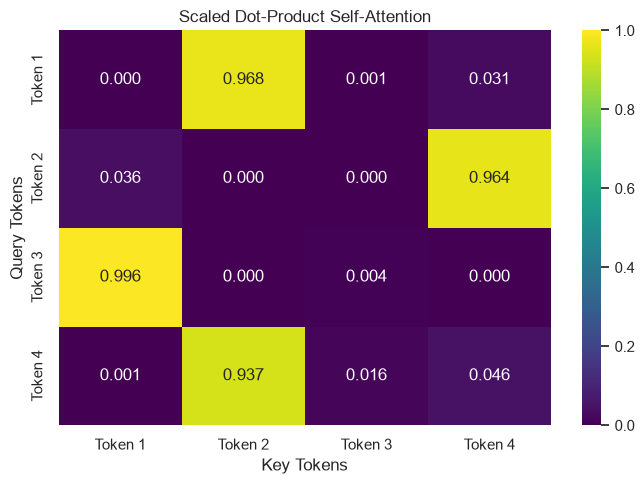

In [14]:

token_labels = ["Token 1", "Token 2", "Token 3", "Token 4"]

plt.figure(figsize=(7, 5))

sns.heatmap(
    attention_weights,
    annot=True,
    fmt=".3f",
    cmap="viridis",
    xticklabels=token_labels,
    yticklabels=token_labels,
    vmin=0,
    vmax=1
)

plt.title("Scaled Dot-Product Self-Attention")
plt.xlabel("Key Tokens")
plt.ylabel("Query Tokens")
plt.tight_layout()
plt.savefig(
    "plots/task2_scaled_dot_product_attention.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


## Task 2.3 — Why divide by \(\sqrt{d_k}\)?


### Why Is Attention Divided by the Square Root of the Key Dimension?

When the feature dimension increases, the magnitude and variance of dot-product scores can increase. Large scores can push softmax toward a saturated distribution where one probability dominates. Dividing by the square root of the key dimension helps control the score scale and can produce more useful gradients during training. We will compare the maximum softmax probability and entropy to observe the effect.


## Run the scaling experiment

In [15]:

np.random.seed(42)

def attention_scaling_experiment(d_k, n_tokens=20):
    Q_test = np.random.randn(n_tokens, d_k)
    K_test = np.random.randn(n_tokens, d_k)

    raw_scores = Q_test @ K_test.T

    results = []

    for scaled in [False, True]:
        if scaled:
            current_scores = raw_scores / np.sqrt(d_k)
            case = "With scaling"
        else:
            current_scores = raw_scores
            case = "Without scaling"

        weights = softmax(current_scores, axis=-1)

        # Entropy per query row
        entropy = -np.sum(
            weights * np.log(np.clip(weights, 1e-12, 1.0)),
            axis=-1
        )

        results.append({
            "d_k": d_k,
            "Case": case,
            "Mean maximum probability": weights.max(axis=-1).mean(),
            "Mean entropy": entropy.mean()
        })

    return results


experiment_results = []

for dimension in [4, 256]:
    experiment_results.extend(
        attention_scaling_experiment(dimension)
    )

scaling_df = pd.DataFrame(experiment_results)
display(scaling_df.round(4))


,d_k,Case,Mean maximum probability,Mean entropy
0,4,Without scaling,0.3439,2.1027
1,4,With scaling,0.1713,2.6929
2,256,Without scaling,0.9232,0.1839
3,256,With scaling,0.2176,2.5853


## Plot the scaling results

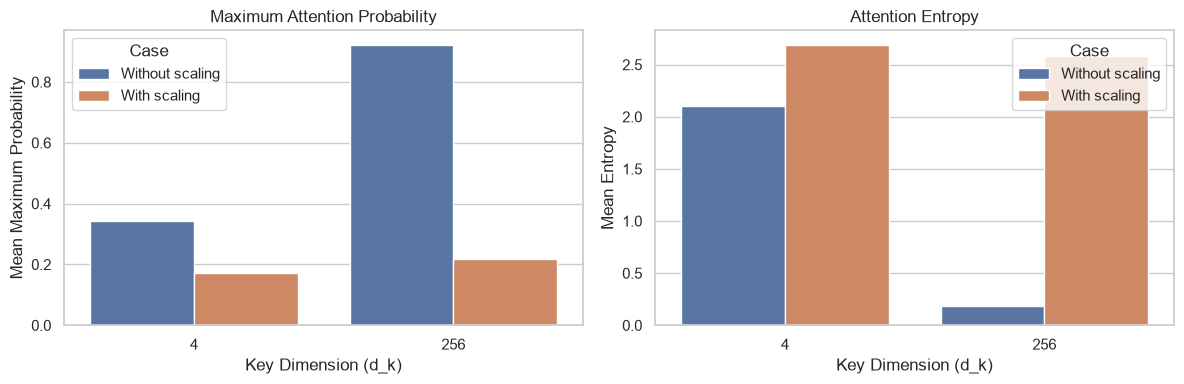

In [16]:

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.barplot(
    data=scaling_df,
    x="d_k",
    y="Mean maximum probability",
    hue="Case",
    ax=axes[0]
)
axes[0].set_title("Maximum Attention Probability")
axes[0].set_xlabel("Key Dimension (d_k)")
axes[0].set_ylabel("Mean Maximum Probability")

sns.barplot(
    data=scaling_df,
    x="d_k",
    y="Mean entropy",
    hue="Case",
    ax=axes[1]
)
axes[1].set_title("Attention Entropy")
axes[1].set_xlabel("Key Dimension (d_k)")
axes[1].set_ylabel("Mean Entropy")

plt.tight_layout()
plt.savefig(
    "plots/task2_attention_scaling_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()



### Scaling Experiment Conclusion

Scaling controls the magnitude of dot-product attention scores. Without scaling, higher-dimensional Query and Key vectors can produce large scores, causing softmax to concentrate its probability on a few tokens. Dividing by the square root of the key dimension helps keep the score distribution at a more manageable scale. The experiment illustrates why scaled dot-product attention is used in Transformer architectures.


## Task 2.4 — Self-attention vs Luong dot attention


### Luong Dot Attention

Luong dot attention calculates the dot product between a decoder hidden state and each encoder hidden state. The resulting scores are converted into attention weights using softmax. These weights combine the encoder hidden states into a context vector. Unlike self-attention, which allows each token to attend to all tokens in the same sequence, this form of Luong attention uses a decoder state to attend over encoder states.


## Implement Luong dot attention in NumPy

In [17]:

np.random.seed(42)

# Five encoder hidden states, each with 8 features
encoder_states = np.random.randn(5, 8)

# One decoder hidden state
decoder_state = np.random.randn(8)

# Calculate dot-product scores
luong_scores = encoder_states @ decoder_state

# Normalize scores
luong_weights = softmax(luong_scores)

# Weighted sum of encoder hidden states
context_vector = luong_weights @ encoder_states

print("Encoder states shape:", encoder_states.shape)
print("Decoder state shape:", decoder_state.shape)
print("Luong scores shape:", luong_scores.shape)
print("Luong weights shape:", luong_weights.shape)
print("Context vector shape:", context_vector.shape)

print("\nLuong scores:\n", luong_scores)
print("\nLuong attention weights:\n", luong_weights)
print("\nContext vector:\n", context_vector)

print("\nSum of attention weights:", luong_weights.sum())


Encoder states shape: (5, 8)
Decoder state shape: (8,)
Luong scores shape: (5,)
Luong weights shape: (5,)
Context vector shape: (8,)

Luong scores:
 [ 0.40818741  1.1597874  -3.70553788  2.97027193  2.00301742]

Luong attention weights:
 [0.04755781 0.10084111 0.00077742 0.61648294 0.23434072]

Context vector:
 [-0.36327268 -0.13110175 -0.53344695 -0.03011265 -0.30693492 -0.8433026
 -0.78097616  1.1667187 ]

Sum of attention weights: 0.9999999999999999


## Create the comparison table

In [18]:

comparison = pd.DataFrame({
    "Feature": [
        "Where Q comes from",
        "Where K comes from",
        "Where V comes from",
        "What is attended over",
        "RNN required?",
        "Parallelism",
        "Typical architecture location"
    ],
    "Luong Dot Attention": [
        "Decoder hidden state",
        "Encoder hidden states",
        "Encoder hidden states",
        "Encoder states for a decoder step",
        "In the original seq2seq setup, commonly yes",
        "Attention is computed per decoder step",
        "Encoder-decoder sequence-to-sequence models"
    ],
    "Self-Attention": [
        "Input token representations",
        "Input token representations",
        "Input token representations",
        "Tokens in the same sequence",
        "No",
        "All sequence positions can be processed in parallel",
        "Transformer encoder and decoder blocks"
    ]
})

display(comparison)


,Feature,Luong Dot Attention,Self-Attention
0,Where Q comes from,Decoder hidden state,Input token representations
1,Where K comes from,Encoder hidden states,Input token representations
2,Where V comes from,Encoder hidden states,Input token representations
3,What is attended over,Encoder states for a decoder step,Tokens in the same sequence
4,RNN required?,"In the original seq2seq setup, commonly yes",No
5,Parallelism,Attention is computed per decoder step,All sequence positions can be processed in par...
6,Typical architecture location,Encoder-decoder sequence-to-sequence models,Transformer encoder and decoder blocks



### Luong Attention vs Self-Attention

Both mechanisms use attention weights to combine information from hidden representations. In Luong dot attention, a decoder state attends to encoder states to obtain information from the source sequence. In self-attention, Queries, Keys and Values are projected from the same input sequence. Transformer self-attention does not require an RNN and can process token positions in parallel, while causal decoder self-attention restricts access to future tokens.


## Task 2.5 — Demonstrate that self-attention is order-blind

## Shuffle the input and compare outputs

In [19]:

# Original self-attention output
_, _, original_weights, original_output = (
    scaled_dot_product_attention(Q, K, V)
)

# Fixed permutation of token rows
permutation = np.array([2, 0, 3, 1])

X_shuffled = X[permutation]

# Apply the same projection matrices to shuffled input
Q_shuffled = X_shuffled @ Wq
K_shuffled = X_shuffled @ Wk
V_shuffled = X_shuffled @ Wv

_, _, shuffled_weights, shuffled_output = (
    scaled_dot_product_attention(
        Q_shuffled,
        K_shuffled,
        V_shuffled
    )
)

# Expected output in shuffled order
expected_shuffled_output = original_output[permutation]

print("Permutation:", permutation)
print("\nOriginal output shape:", original_output.shape)
print("Shuffled output shape:", shuffled_output.shape)

print(
    "\nShuffled output matches permuted original output:",
    np.allclose(shuffled_output, expected_shuffled_output)
)

# Restore the original order
inverse_permutation = np.argsort(permutation)
restored_output = shuffled_output[inverse_permutation]

print(
    "Restored output matches original output:",
    np.allclose(restored_output, original_output)
)


Permutation: [2 0 3 1]

Original output shape: (4, 8)
Shuffled output shape: (4, 8)

Shuffled output matches permuted original output: True
Restored output matches original output: True



### Why Does Self-Attention Need Positional Encoding?

Self-attention calculates relationships between token representations but does not inherently identify their absolute positions. When token rows are shuffled, the corresponding output rows are shuffled in the same order. The demonstration confirms this property for our implementation. Transformers therefore add positional information so the model can distinguish identical words appearing at different positions.


## Task 2.6 — Verify our attention against real DistilBERT

## Load DistilBERT with attention outputs enabled

In [20]:

import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from transformers import AutoTokenizer, AutoModel

real_model_name = "distilbert-base-uncased-finetuned-sst-2-english"

real_tokenizer = AutoTokenizer.from_pretrained(real_model_name)

real_model = AutoModel.from_pretrained(
    real_model_name,
    attn_implementation="eager"
)

real_model.eval()

print("Model loaded successfully.")
print("Number of layers:", real_model.config.n_layers)
print("Number of heads:", real_model.config.n_heads)
print("Hidden size:", real_model.config.dim)

# Inspect the model's module structure
print("\nFirst Transformer layer:")
print(real_model.transformer.layer[0])


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased-finetuned-sst-2-english
Key                   | Status     |  | 
----------------------+------------+--+-
pre_classifier.weight | UNEXPECTED |  | 
classifier.bias       | UNEXPECTED |  | 
classifier.weight     | UNEXPECTED |  | 
pre_classifier.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Model loaded successfully.
Number of layers: 6
Number of heads: 12
Hidden size: 768

First Transformer layer:
TransformerBlock(
  (attention): DistilBertSelfAttention(
    (q_lin): Linear(in_features=768, out_features=768, bias=True)
    (k_lin): Linear(in_features=768, out_features=768, bias=True)
    (v_lin): Linear(in_features=768, out_features=768, bias=True)
    (out_lin): Linear(in_features=768, out_features=768, bias=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (sa_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
  (ffn): FFN(
    (dropout): Dropout(p=0.1, inplace=False)
    (lin1): Linear(in_features=768, out_features=3072, bias=True)
    (lin2): Linear(in_features=3072, out_features=768, bias=True)
    (activation): GELUActivation()
  )
  (output_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
)


## Run a sentence through the real model

In [21]:

verification_text = "The animal did not cross the street because it was too tired."

inputs = real_tokenizer(
    verification_text,
    return_tensors="pt"
)

with torch.no_grad():
    outputs = real_model(
        **inputs,
        output_hidden_states=True,
        output_attentions=True
    )

hidden_states = outputs.hidden_states
attentions = outputs.attentions

print("Number of hidden-state tensors:", len(hidden_states))
print("Number of attention tensors:", len(attentions))

print("\nInput IDs shape:", tuple(inputs["input_ids"].shape))
print("Embedding output shape:", tuple(hidden_states[0].shape))
print("Layer 0 attention shape:", tuple(attentions[0].shape))

print("\nTokens:")
print(real_tokenizer.convert_ids_to_tokens(
    inputs["input_ids"][0].tolist()
))


Number of hidden-state tensors: 7
Number of attention tensors: 6

Input IDs shape: (1, 15)
Embedding output shape: (1, 15, 768)
Layer 0 attention shape: (1, 12, 15, 15)

Tokens:
['[CLS]', 'the', 'animal', 'did', 'not', 'cross', 'the', 'street', 'because', 'it', 'was', 'too', 'tired', '.', '[SEP]']


## Recompute layer 0, head 0 attention manually

In [22]:

# DistilBERT's first Transformer layer
first_layer = real_model.transformer.layer[0]
num_heads = real_model.config.n_heads
head_dim = real_model.config.dim // num_heads

# Input to the first Transformer layer
with torch.no_grad():
    hidden = real_model.embeddings(
        input_ids=inputs["input_ids"]
    )

    # Manual Q and K projections
    q = first_layer.attention.q_lin(hidden)
    k = first_layer.attention.k_lin(hidden)

    batch_size, seq_length, hidden_size = q.shape

    # Split hidden dimensions into attention heads
    q = q.view(
        batch_size, seq_length, num_heads, head_dim
    ).transpose(1, 2)

    k = k.view(
        batch_size, seq_length, num_heads, head_dim
    ).transpose(1, 2)

    # Calculate scaled dot-product scores
    manual_scores = q @ k.transpose(-1, -2)
    manual_scores = manual_scores / np.sqrt(head_dim)

    # No padding exists in this single unpadded input
    manual_weights = torch.softmax(manual_scores, dim=-1)

# Compare first batch, first head
manual_head_0 = manual_weights[0, 0].cpu().numpy()
model_head_0 = attentions[0][0, 0].cpu().numpy()

print("Manual attention shape:", manual_head_0.shape)
print("Model attention shape:", model_head_0.shape)

print("\nManual attention matrix:")
print(manual_head_0)

print("\nModel attention matrix:")
print(model_head_0)


Manual attention shape: (15, 15)
Model attention shape: (15, 15)

Manual attention matrix:
[[0.06436036 0.05267455 0.05166699 0.05027309 0.03349586 0.05245318
  0.07950401 0.06033599 0.05688442 0.04876898 0.04460216 0.03994236
  0.0800041  0.08622795 0.198806  ]
 [0.24725309 0.04727045 0.02798082 0.07075547 0.06461388 0.03658861
  0.05208686 0.02743757 0.05515046 0.04963476 0.07315991 0.05855975
  0.08087472 0.05340327 0.05523044]
 [0.11020921 0.01414977 0.06710996 0.0773217  0.03065385 0.05636056
  0.01530446 0.16867292 0.02575263 0.02933889 0.08293179 0.06134148
  0.18780449 0.02960305 0.04344522]
 [0.15303579 0.0337604  0.03661972 0.05530324 0.15779643 0.03749378
  0.03362516 0.01940744 0.10544364 0.05974439 0.03685889 0.07521452
  0.09379319 0.06836258 0.03354082]
 [0.22218436 0.03082602 0.03726225 0.05500141 0.03950682 0.0324396
  0.028224   0.02928606 0.10685826 0.06420021 0.07067648 0.07147517
  0.06868572 0.06602604 0.07734763]
 [0.22648609 0.01232268 0.09939003 0.07434373 0.02

## Compare both attention matrices

In [23]:

max_difference = np.max(
    np.abs(manual_head_0 - model_head_0)
)

print("Maximum absolute difference:", max_difference)

print(
    "Attention matrices match within tolerance:",
    np.allclose(
        manual_head_0,
        model_head_0,
        atol=1e-4,
        rtol=1e-4
    )
)


Maximum absolute difference: 0.0
Attention matrices match within tolerance: True


## Plot the verified attention matrix

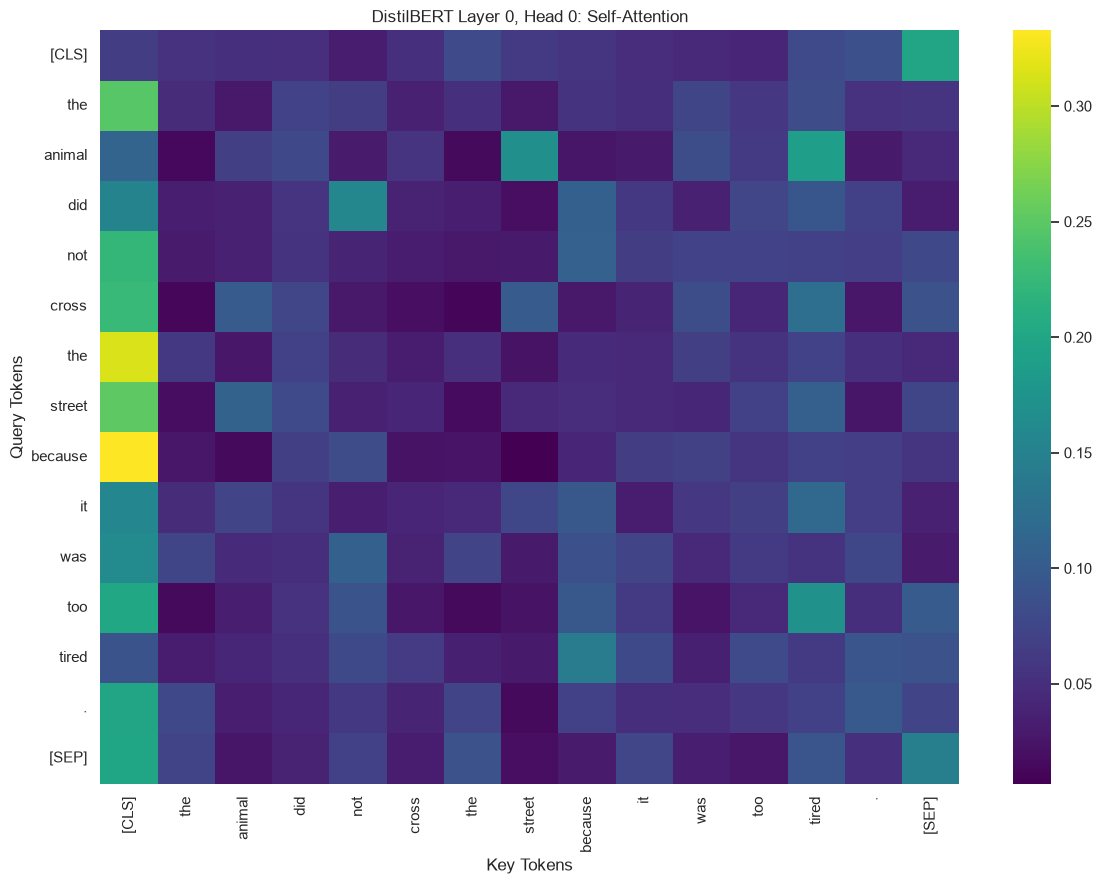

In [24]:

tokens = real_tokenizer.convert_ids_to_tokens(
    inputs["input_ids"][0].tolist()
)

plt.figure(figsize=(12, 9))

sns.heatmap(
    model_head_0,
    xticklabels=tokens,
    yticklabels=tokens,
    cmap="viridis"
)

plt.title("DistilBERT Layer 0, Head 0: Self-Attention")
plt.xlabel("Key Tokens")
plt.ylabel("Query Tokens")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig(
    "plots/task2_distilbert_attention_verification.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


### Verification Against Real DistilBERT

We manually calculated the Query and Key projections from the pretrained DistilBERT model and applied scaled dot-product attention. We then compared our calculated attention matrix with the attention matrix returned by the real model. A close numerical match confirms that our implementation reproduces the attention calculation for the selected layer and head. This connects the mathematical attention equation with a working pretrained Transformer.



## Task 3: Multi-Head Attention, Positional Encoding, and Layer Normalization

### Objectives
1. Understand multi-head attention and attention heads.
2. Extract and visualize real attention heads from DistilBERT.
3. Calculate attention entropy for different layers.
4. Implement sinusoidal positional encoding.
5. Examine pretrained positional embeddings.
6. Implement Layer Normalization using NumPy.
7. Compare Layer Normalization with Batch Normalization.


## Task 3.1 — Understand Multi-Head Attention

## Explanation
In Task 2, you implemented scaled dot-product attention and Luong attention. Now, we will explore how a Transformer uses multiple attention heads simultaneously.

A single attention head learns attention patterns using queries (\(Q\)), keys (\(K\)), and values (\(V\)). Multi-head attention runs several attention heads in parallel and combines their outputs.

For DistilBERT, the configuration is typically:
- Hidden size: 768
- Number of attention heads: 12
- Dimension per head: \(768/12=64\)
Each head has its own query, key, and value projections. The head outputs are concatenated and passed through an output projection.
\[
\operatorname{MultiHead}(Q,K,V)
=\operatorname{Concat}(head_1,\ldots,head_{12})W^O
\]

The heads can learn different attention patterns. However, we should inspect their actual attention maps before interpreting what each head does.

## Task 3.2 — Extract and Visualize Real Attention Heads
## Load the pretrained model and tokenize a sentence

In [25]:

import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from transformers import AutoTokenizer, AutoModel

model_name = "distilbert-base-uncased-finetuned-sst-2-english"

tokenizer = AutoTokenizer.from_pretrained(model_name)

model = AutoModel.from_pretrained(
    model_name,
    attn_implementation="eager"
)

model.eval()

sentence = (
    "The animal did not cross the street "
    "because it was too tired."
)

inputs = tokenizer(
    sentence,
    return_tensors="pt"
)

print("Input sentence:")
print(sentence)

print("\nInput tokens:")
print(tokenizer.convert_ids_to_tokens(inputs["input_ids"][0]))

print("\nInput shape:")
print(inputs["input_ids"].shape)


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased-finetuned-sst-2-english
Key                   | Status     |  | 
----------------------+------------+--+-
pre_classifier.weight | UNEXPECTED |  | 
classifier.bias       | UNEXPECTED |  | 
classifier.weight     | UNEXPECTED |  | 
pre_classifier.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Input sentence:
The animal did not cross the street because it was too tired.

Input tokens:
['[CLS]', 'the', 'animal', 'did', 'not', 'cross', 'the', 'street', 'because', 'it', 'was', 'too', 'tired', '.', '[SEP]']

Input shape:
torch.Size([1, 15])


## Extract attention weights

In [26]:

with torch.no_grad():
    outputs = model(
        **inputs,
        output_attentions=True
    )

attentions = outputs.attentions

print("Number of Transformer layers:", len(attentions))
print("Attention tensor shape:", attentions[0].shape)


Number of Transformer layers: 6
Attention tensor shape: torch.Size([1, 12, 15, 15])


## Plot six attention heads

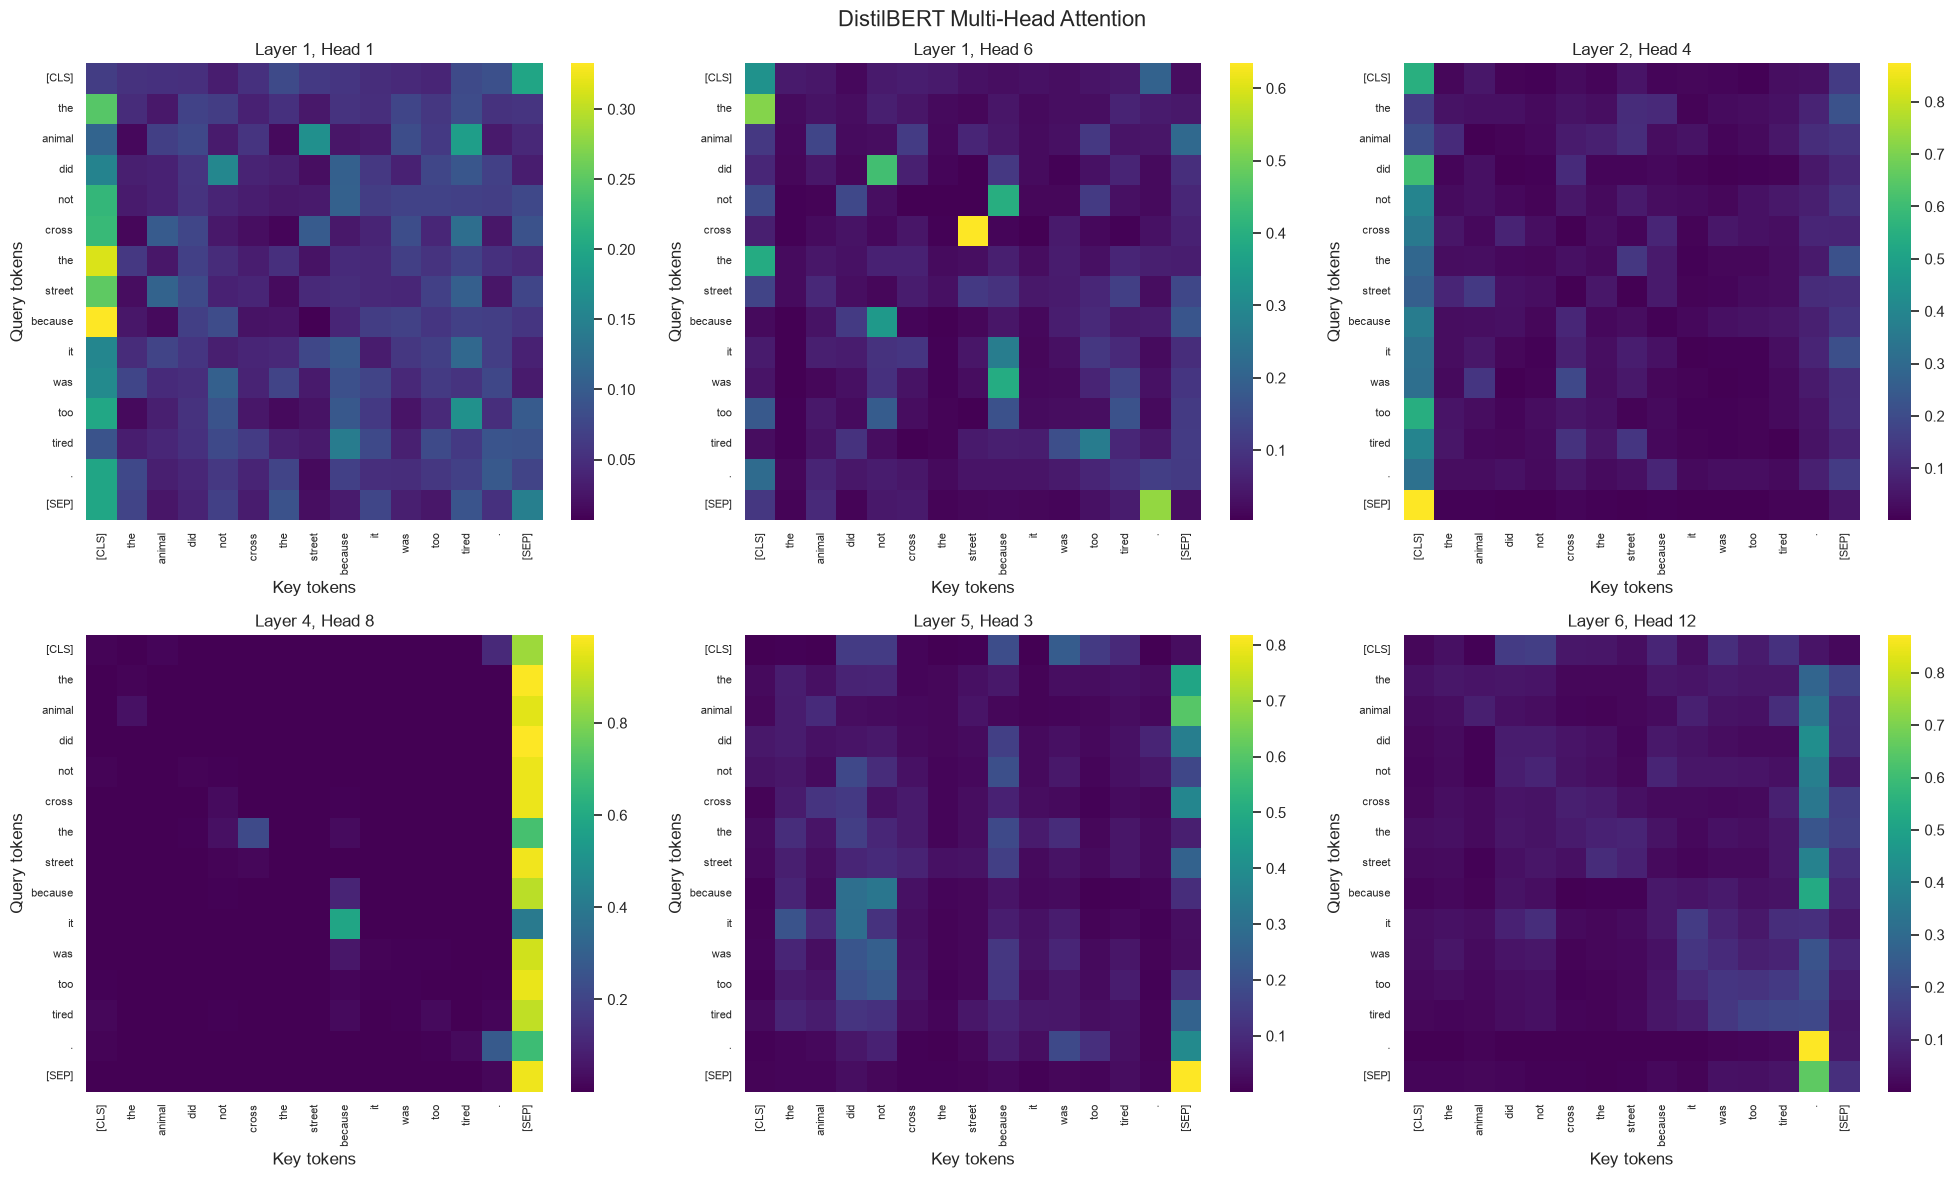

In [27]:

tokens = tokenizer.convert_ids_to_tokens(
    inputs["input_ids"][0]
)

# Choose six heads across the six DistilBERT layers.
selected_heads = [
    (0, 0),
    (0, 5),
    (1, 3),
    (3, 7),
    (4, 2),
    (5, 11)
]

fig, axes = plt.subplots(
    2, 3,
    figsize=(20, 12)
)

for ax, (layer_idx, head_idx) in zip(
    axes.flat, selected_heads
):
    attention_matrix = (
        attentions[layer_idx][0, head_idx]
        .detach()
        .cpu()
        .numpy()
    )

    sns.heatmap(
        attention_matrix,
        xticklabels=tokens,
        yticklabels=tokens,
        cmap="viridis",
        ax=ax
    )

    ax.set_title(
        f"Layer {layer_idx + 1}, Head {head_idx + 1}"
    )
    ax.set_xlabel("Key tokens")
    ax.set_ylabel("Query tokens")

    ax.tick_params(
        axis="x",
        rotation=90,
        labelsize=8
    )
    ax.tick_params(
        axis="y",
        rotation=0,
        labelsize=8
    )

plt.suptitle(
    "DistilBERT Multi-Head Attention",
    fontsize=16
)
plt.tight_layout()
plt.savefig(
    "plots/task3_six_attention_heads.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()



### Attention Visualization Observations

1. Different attention heads can produce different attention distributions. Some may concentrate attention on nearby tokens, while others distribute attention across more distant tokens.
2. Inspect whether particular tokens, such as punctuation or special tokens `[CLS]` and `[SEP]`, receive relatively high attention.
3. Attention maps show where attention weight is assigned, but a high weight alone does not prove that a head has a specific linguistic role.
4. The patterns can vary by layer and attention head.


## Task 3.3 — Calculate Attention Entropy for Each Head

Attention entropy measures how concentrated or spread out an attention distribution is.
- Lower entropy: attention is concentrated on a smaller number of tokens.
- Higher entropy: attention is spread across more tokens.
For an attention distribution \(p_1,\ldots,p_n\):
\[
H(p)=-\sum_{i=1}^{n}p_i\log(p_i)
\]

## Calculate average entropy for the first and last layers

In [28]:

def calculate_attention_entropy(attention_tensor):
    """
    attention_tensor shape:
    (batch_size, num_heads, query_length, key_length)
    """
    attention = attention_tensor.detach().cpu().numpy()

    # Avoid log(0) by replacing zeros with a tiny value.
    attention = np.clip(attention, 1e-12, 1.0)

    # Entropy over the key-token dimension.
    entropy = -np.sum(
        attention * np.log(attention),
        axis=-1
    )

    # Average over batch and query-token positions.
    # Result: one average entropy value per head.
    return entropy.mean(axis=(0, 2))


first_layer_entropy = calculate_attention_entropy(
    attentions[0]
)

last_layer_entropy = calculate_attention_entropy(
    attentions[-1]
)

print("First layer entropy by head:")
print(np.round(first_layer_entropy, 4))

print("\nLast layer entropy by head:")
print(np.round(last_layer_entropy, 4))


First layer entropy by head:
[2.4939 2.0654 0.5533 1.2512 2.3135 2.1365 2.2454 1.6157 1.7954 1.2444
 0.6994 1.8173]

Last layer entropy by head:
[2.0346 1.8619 2.2673 1.8916 1.9279 1.9788 1.993  1.7625 1.9481 2.2913
 2.0655 2.0924]


## Plot the entropy comparison

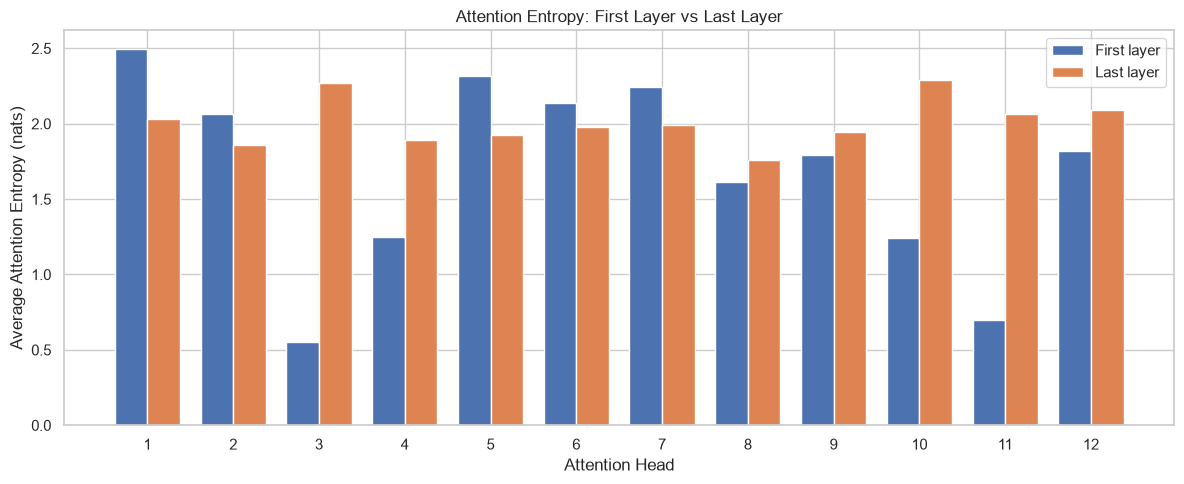

In [29]:

head_numbers = np.arange(1, len(first_layer_entropy) + 1)

plt.figure(figsize=(12, 5))

bar_width = 0.38

plt.bar(
    head_numbers - bar_width / 2,
    first_layer_entropy,
    width=bar_width,
    label="First layer"
)

plt.bar(
    head_numbers + bar_width / 2,
    last_layer_entropy,
    width=bar_width,
    label="Last layer"
)

plt.xlabel("Attention Head")
plt.ylabel("Average Attention Entropy (nats)")
plt.title("Attention Entropy: First Layer vs Last Layer")
plt.xticks(head_numbers)
plt.legend()
plt.tight_layout()
plt.savefig(
    "plots/task3_attention_entropy_by_head.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


## Calculate and interpret the layer averages

In [30]:

print(
    "First layer mean entropy:",
    round(float(first_layer_entropy.mean()), 4)
)

print(
    "Last layer mean entropy:",
    round(float(last_layer_entropy.mean()), 4)
)


First layer mean entropy: 1.686
Last layer mean entropy: 2.0096



### Entropy Interpretation

Attention entropy measures how broadly each query token distributes its attention over the key tokens. Lower entropy indicates a more concentrated distribution, while higher entropy indicates a more distributed one.

The first and last layers may have different entropy patterns. The observed difference should be described using the numerical results from this experiment; lower or higher entropy alone does not establish that a layer is more intelligent or better.


## Task 3.4 — Implement Sinusoidal Positional Encoding
Why do Transformers need positional encoding?
Self-attention processes token representations through attention operations, but attention by itself does not inherently encode the sequence order. Positional information helps the model distinguish between sequences that contain the same words in different orders.

The original sinusoidal positional encoding uses sine and cosine functions at different frequencies:
\[
PE(pos,2i)=\sin\left(\frac{pos}{10000^{2i/d_{\text{model}}}}\right)
\]

\[
PE(pos,2i+1)=\cos\left(\frac{pos}{10000^{2i/d_{\text{model}}}}\right)
\]

Here:
- pos is the token position.
- i identifies a dimension pair.
- d_model is the embedding dimension.

## Create positional encoding using NumPy

In [31]:

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

def sinusoidal_positional_encoding(
    max_positions,
    d_model
):
    """
    Returns a positional encoding matrix with shape:
    (max_positions, d_model)
    """
    positions = np.arange(max_positions)[:, np.newaxis]

    dimensions = np.arange(d_model)[np.newaxis, :]

    angle_rates = 1 / np.power(
        10000,
        (2 * (dimensions // 2)) / d_model
    )

    angle_radians = positions * angle_rates

    positional_encoding = np.zeros(
        (max_positions, d_model)
    )

    # Even dimensions use sine.
    positional_encoding[:, 0::2] = np.sin(
        angle_radians[:, 0::2]
    )

    # Odd dimensions use cosine.
    positional_encoding[:, 1::2] = np.cos(
        angle_radians[:, 1::2]
    )

    return positional_encoding


max_positions = 50
d_model = 128

pos_encoding = sinusoidal_positional_encoding(
    max_positions=max_positions,
    d_model=d_model
)

print("Positional encoding shape:", pos_encoding.shape)
print("\nFirst position, first 10 dimensions:")
print(np.round(pos_encoding[0, :10], 4))


Positional encoding shape: (50, 128)

First position, first 10 dimensions:
[0. 1. 0. 1. 0. 1. 0. 1. 0. 1.]


## Visualize the positional encoding matrix

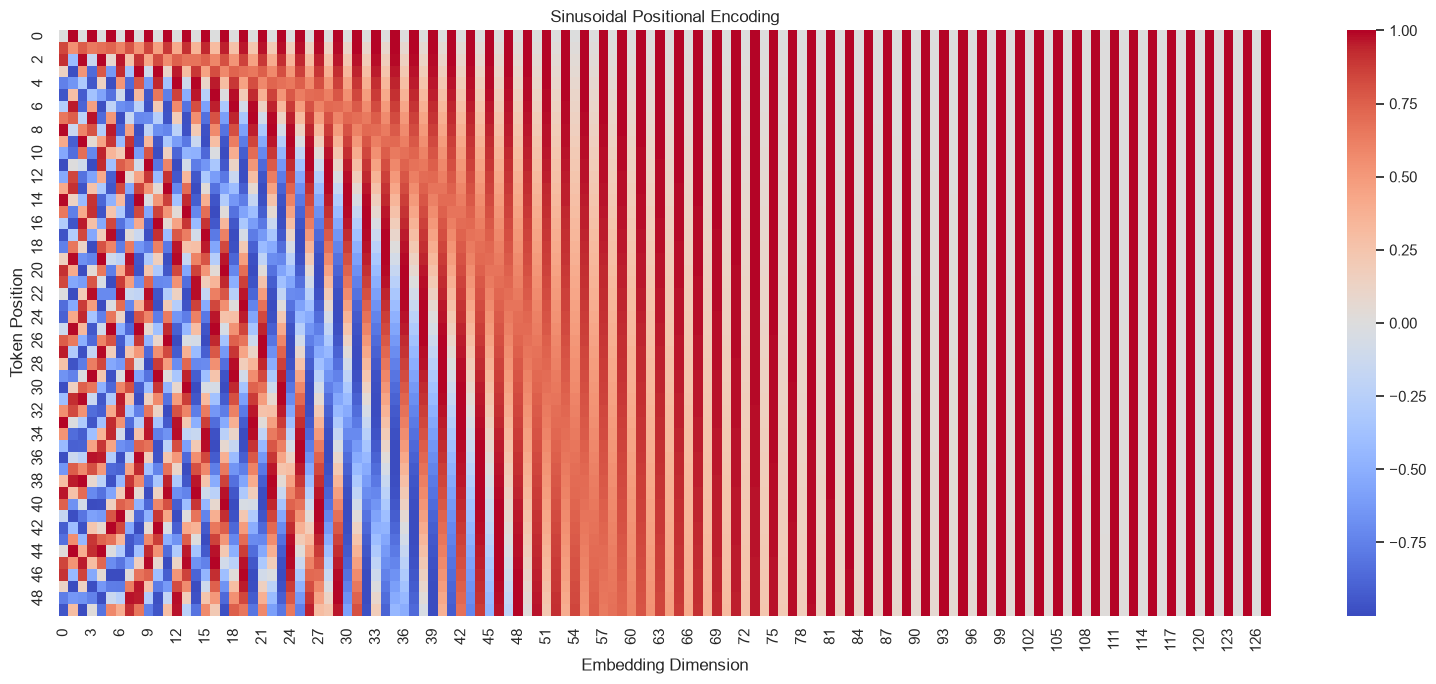

In [32]:

plt.figure(figsize=(16, 7))

sns.heatmap(
    pos_encoding,
    cmap="coolwarm",
    center=0
)

plt.title("Sinusoidal Positional Encoding")
plt.xlabel("Embedding Dimension")
plt.ylabel("Token Position")
plt.tight_layout()
plt.savefig(
    "plots/task3_sinusoidal_positional_encoding.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


### Positional Encoding Observations

1. Each row represents the positional encoding for a token position.
2. Each column represents one embedding dimension.
3. Different dimensions use different sinusoidal frequencies.
4. Even dimensions use sine, while odd dimensions use cosine.
5. The resulting patterns provide the Transformer with information about token positions.

Sinusoidal positional encoding is a mathematical way to represent sequence positions without learning a separate vector for every position during model training.


## Task 3.5 — Demonstrate How Position Changes a Word Representation
We will create a random word embedding and add the positional encodings for positions 3 and 20. We will then compare cosine similarity with and without positional encoding.

Cosine similarity is:
\[
\operatorname{cos}(a,b)=
\frac{a\cdot b}{\|a\|\|b\|}
\]

## Compare representations at two positions

In [33]:

np.random.seed(42)

d_model = 128

# Simulated word embedding.
word_embedding = np.random.randn(d_model)

position_3 = 3
position_20 = 20

pe_3 = pos_encoding[position_3]
pe_20 = pos_encoding[position_20]

# Add positional information to the same word embedding.
representation_3 = word_embedding + pe_3
representation_20 = word_embedding + pe_20


def cosine_similarity(a, b):
    denominator = np.linalg.norm(a) * np.linalg.norm(b)

    if denominator == 0:
        return 0.0

    return float(np.dot(a, b) / denominator)


similarity_without_position = cosine_similarity(
    word_embedding,
    word_embedding
)

similarity_with_position = cosine_similarity(
    representation_3,
    representation_20
)

print(
    "Similarity without positional encoding:",
    round(similarity_without_position, 6)
)

print(
    "Similarity with positional encoding:",
    round(similarity_with_position, 6)
)


Similarity without positional encoding: 1.0
Similarity with positional encoding: 0.859478



### Conclusion: Positional Information

Adding different positional encodings changes the representation of the same word at different sequence positions. This gives a Transformer a way to represent both token identity and position.

The experiment demonstrates the mathematical effect of positional encoding. It does not establish that the resulting representations are semantically better; that would require an evaluation of a trained model.


## Task 3.6 — Inspect DistilBERT’s Learned Positional Embeddings
The sinusoidal encoding above was created mathematically. DistilBERT, however, uses learned positional embeddings: the model has a trainable embedding vector for each supported position.

## Inspect the pretrained positional embedding matrix

In [34]:

# Access positional embeddings directly from DistilBertModel
position_embeddings = (
    model.embeddings.position_embeddings.weight
)

position_array = (
    position_embeddings.detach()
    .cpu()
    .numpy()
)

print("Positional embedding shape:", position_array.shape)

print("\nFirst position, first 10 dimensions:")
print(np.round(position_array[0, :10], 4))


Positional embedding shape: (512, 768)

First position, first 10 dimensions:
[ 0.018  -0.0238 -0.036  -0.0238  0.0096 -0.0178 -0.0025 -0.0037  0.0064
 -0.0392]


## Calculate cosine similarities between positions

In [35]:

from sklearn.metrics.pairwise import cosine_similarity

num_positions_to_plot = 64

selected_positions = position_array[
    :num_positions_to_plot
]

position_similarity = cosine_similarity(
    selected_positions
)

print("Similarity matrix shape:", position_similarity.shape)


Similarity matrix shape: (64, 64)


## Plot the positional similarity matrix

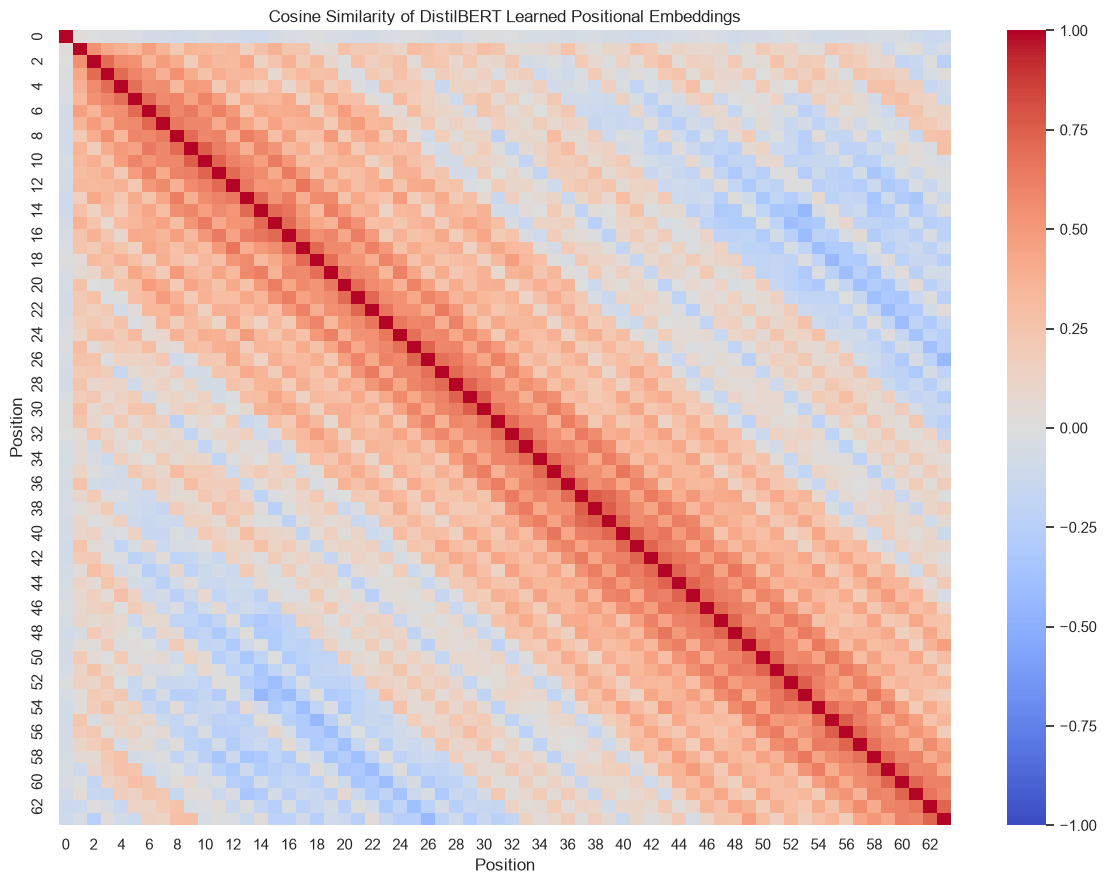

In [36]:

plt.figure(figsize=(12, 9))

sns.heatmap(
    position_similarity,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title(
    "Cosine Similarity of DistilBERT Learned Positional Embeddings"
)
plt.xlabel("Position")
plt.ylabel("Position")
plt.tight_layout()
plt.savefig(
    "plots/task3_learned_position_similarity.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


### Learned Positional Embedding Observations

1. Each position has a learned vector in the pretrained model.
2. The diagonal of the cosine similarity matrix is approximately 1 because each position is compared with itself.
3. Off-diagonal values show the cosine similarity between different positional vectors.
4. Unlike fixed sinusoidal encoding, these positional vectors are learned during model training.
5. Standard DistilBERT has a positional embedding table supporting up to 512 positions. The usable input length also depends on special tokens and the model configuration.

T5 uses a different positional-information approach, based on relative position biases in its attention mechanism, rather than DistilBERT's learned absolute position embedding table.


## Task 3.7 — Implement Layer Normalization Using NumPy
Layer Normalization normalizes each token's feature vector independently. For each token, it calculates the mean and variance across the feature dimension.
\[
\mu=\frac{1}{d}\sum_{i=1}^{d}x_i
\]

\[
\sigma^2=\frac{1}{d}\sum_{i=1}^{d}(x_i-\mu)^2
\]

\[
\operatorname{LayerNorm}(x)=
\frac{x-\mu}{\sqrt{\sigma^2+\epsilon}}\gamma+\beta
\]

Here, \(\gamma\) and \(\beta\) are learnable scale and shift parameters. Initially, our demonstration will use \(\gamma=1\) and \(\beta=0\).

## Create a small input matrix

In [37]:

import numpy as np
import torch
import torch.nn as nn

np.random.seed(42)

# Four tokens, each with eight features.
X = np.random.randn(4, 8).astype(np.float32)

print("Input matrix:")
print(np.round(X, 3))

print("\nInput shape:", X.shape)


Input matrix:
[[ 0.497 -0.138  0.648  1.523 -0.234 -0.234  1.579  0.767]
 [-0.469  0.543 -0.463 -0.466  0.242 -1.913 -1.725 -0.562]
 [-1.013  0.314 -0.908 -1.412  1.466 -0.226  0.068 -1.425]
 [-0.544  0.111 -1.151  0.376 -0.601 -0.292 -0.602  1.852]]

Input shape: (4, 8)


## Implement Layer Normalization in NumPy

In [38]:

def numpy_layer_norm(
    X,
    gamma=None,
    beta=None,
    eps=1e-5
):
    # Normalize features independently for every token.
    mean = np.mean(X, axis=-1, keepdims=True)

    # Population variance across each token's features.
    variance = np.var(X, axis=-1, keepdims=True)

    normalized = (
        (X - mean) / np.sqrt(variance + eps)
    )

    if gamma is None:
        gamma = np.ones(X.shape[-1], dtype=X.dtype)

    if beta is None:
        beta = np.zeros(X.shape[-1], dtype=X.dtype)

    return normalized * gamma + beta


numpy_result = numpy_layer_norm(X)

print("NumPy LayerNorm output:")
print(np.round(numpy_result, 4))


NumPy LayerNorm output:
[[-0.079  -1.0041  0.1409  1.4162 -1.1438 -1.1437  1.498   0.3154]
 [ 0.1664  1.439   0.174   0.1711  1.061  -1.6491 -1.4122  0.0497]
 [-0.6661  0.7579 -0.5537 -1.0948  1.9934  0.1784  0.4931 -1.1082]
 [-0.5091  0.2525 -1.2141  0.5602 -0.5745 -0.2154 -0.5757  2.2762]]


## Compare NumPy with PyTorch

In [39]:

torch_layer_norm = nn.LayerNorm(
    normalized_shape=8,
    eps=1e-5,
    elementwise_affine=True
)

# Explicitly use gamma = 1 and beta = 0.
with torch.no_grad():
    torch_layer_norm.weight.fill_(1.0)
    torch_layer_norm.bias.fill_(0.0)

torch_result = torch_layer_norm(
    torch.tensor(X)
).detach().cpu().numpy()

print("PyTorch LayerNorm output:")
print(np.round(torch_result, 4))

print(
    "\nOutputs are close:",
    np.allclose(
        numpy_result,
        torch_result,
        atol=1e-5
    )
)

print(
    "Maximum absolute difference:",
    np.max(np.abs(numpy_result - torch_result))
)


PyTorch LayerNorm output:
[[-0.079  -1.0041  0.1409  1.4162 -1.1438 -1.1437  1.498   0.3154]
 [ 0.1664  1.439   0.174   0.1711  1.061  -1.6491 -1.4122  0.0497]
 [-0.6661  0.7579 -0.5537 -1.0948  1.9934  0.1784  0.4931 -1.1082]
 [-0.5091  0.2525 -1.2141  0.5602 -0.5745 -0.2154 -0.5757  2.2762]]

Outputs are close: True
Maximum absolute difference: 2.3841858e-07


## Check the statistics for each token

In [40]:

print("Mean of each normalized token:")
print(np.round(numpy_result.mean(axis=1), 6))

print("\nVariance of each normalized token:")
print(np.round(numpy_result.var(axis=1), 6))


Mean of each normalized token:
[-0.  0.  0. -0.]

Variance of each normalized token:
[0.999979 0.999984 0.999988 0.999987]


## Task 3.8 — Compare Layer Normalization with Batch Normalization
The key difference is the dimension across which normalization occurs.
- Layer Normalization: normalizes the features of each token independently.
- Batch Normalization: in this example, normalizes each feature across the four tokens in the batch.

## Implement a simple Batch Normalization demonstration

In [41]:

def numpy_batch_norm(X, eps=1e-5):
    """
    Demonstration for a matrix shaped:
    (batch_or_tokens, features)

    Normalize each feature across the rows.
    """
    feature_mean = np.mean(X, axis=0, keepdims=True)
    feature_variance = np.var(X, axis=0, keepdims=True)

    normalized = (
        (X - feature_mean)
        / np.sqrt(feature_variance + eps)
    )

    return normalized


batch_norm_result = numpy_batch_norm(X)

print("BatchNorm demonstration output:")
print(np.round(batch_norm_result, 4))

print("\nFeature means across rows:")
print(np.round(batch_norm_result.mean(axis=0), 6))

print("\nFeature variances across rows:")
print(np.round(batch_norm_result.var(axis=0), 6))


BatchNorm demonstration output:
[[ 1.6024 -1.3754  1.6177  1.4044 -0.5802  0.5997  1.4627  0.4868]
 [-0.1585  1.3339  0.0076 -0.4357  0.0305 -1.731  -1.3003 -0.5756]
 [-1.1489  0.4253 -0.6366 -1.3116  1.5999  0.6114  0.1986 -1.2647]
 [-0.2951 -0.3838 -0.9887  0.3428 -1.0502  0.5199 -0.361   1.3536]]

Feature means across rows:
[-0.  0. -0.  0.  0.  0. -0.  0.]

Feature variances across rows:
[0.999967 0.999842 0.999979 0.999991 0.999984 0.999981 0.999993 0.999994]


## Compare the normalization statistics

In [42]:

print("LayerNorm: mean and variance for each token")
print("Means:", np.round(numpy_result.mean(axis=1), 4))
print("Variances:", np.round(numpy_result.var(axis=1), 4))

print("\nBatchNorm: mean and variance for each feature")
print("Means:", np.round(batch_norm_result.mean(axis=0), 4))
print("Variances:", np.round(batch_norm_result.var(axis=0), 4))


LayerNorm: mean and variance for each token
Means: [-0.  0.  0. -0.]
Variances: [1. 1. 1. 1.]

BatchNorm: mean and variance for each feature
Means: [-0.  0. -0.  0.  0.  0. -0.  0.]
Variances: [1.     0.9998 1.     1.     1.     1.     1.     1.    ]



### Layer Normalization vs Batch Normalization

| Feature | Layer Normalization | Batch Normalization |
|---|---|---|
| Normalization axis | Features within each token | Batch or token rows for each feature in this example |
| Statistics | Computed independently for each token | Computed across rows for each feature |
| Dependence on batch size | Does not depend on other examples in the batch | Batch statistics depend on the rows included |
| Sequence lengths | Naturally fits variable-length token representations | Requires care when padding or masking affects statistics |
| Transformer usage | Commonly used in Transformer blocks | Not the standard normalization used in Transformer blocks |

Transformers commonly use Layer Normalization because it normalizes each token's feature representation without relying on statistics from other tokens or examples in the batch.


## Task 3.9 — Inspect DistilBERT’s Learned Layer Normalization Parameters
Layer Normalization can learn two parameters:
- \(\gamma\): scales normalized features.
- \(\beta\): shifts normalized features.
DistilBERT uses Layer Normalization in its embedding module and Transformer blocks.

## Print the embedding LayerNorm parameters

In [43]:

# Access embedding LayerNorm directly from DistilBertModel
embedding_layer_norm = model.embeddings.LayerNorm

gamma = (
    embedding_layer_norm.weight.detach()
    .cpu()
    .numpy()
)

beta = (
    embedding_layer_norm.bias.detach()
    .cpu()
    .numpy()
)

print("Gamma shape:", gamma.shape)
print("Beta shape:", beta.shape)

print("\nFirst 10 gamma values:")
print(np.round(gamma[:10], 4))

print("\nFirst 10 beta values:")
print(np.round(beta[:10], 4))

print("\nGamma mean:", round(float(gamma.mean()), 4))
print("Beta mean:", round(float(beta.mean()), 4))


Gamma shape: (768,)
Beta shape: (768,)

First 10 gamma values:
[0.8445 0.7974 0.7331 0.7594 0.8013 0.7861 0.817  0.8177 0.8369 0.7073]

First 10 beta values:
[ 0.0443  0.0614  0.0692  0.0874 -0.0584 -0.1601  0.1443 -0.0606 -0.0279
  0.1222]

Gamma mean: 0.7444
Beta mean: -0.01



## Task 3: Final Summary

In this task, I explored the following Transformer concepts:

1. **Multi-head attention:** multiple attention heads process token representations in parallel.
2. **Attention visualization:** real attention matrices from pretrained DistilBERT were extracted and plotted.
3. **Attention entropy:** entropy was used to measure how concentrated or distributed attention weights are.
4. **Sinusoidal positional encoding:** implemented using NumPy and visualized with a heatmap.
5. **Learned positional embeddings:** inspected DistilBERT's pretrained positional embedding matrix.
6. **Layer Normalization:** implemented LayerNorm using NumPy and verified the result against PyTorch.
7. **Batch Normalization:** compared the normalization axes and statistics with Layer Normalization.
8. **Learnable parameters:** inspected the gamma and beta parameters of DistilBERT's embedding LayerNorm.

### Conclusion

Multi-head attention allows a Transformer to represent different attention patterns, while positional information helps represent token order. Layer Normalization stabilizes token representations by normalizing features independently for each token.


## Task 4.1 — Understand the Transformer Encoder Architecture

# Task 4: Transformer Encoder Architecture and Masked Attention

## Objectives
1. Understand the Transformer encoder architecture.
2. Inspect DistilBERT's modules and parameters.
3. Group model parameters by component.
4. Use masked language modeling to predict missing words.
5. Visualize bidirectional encoder attention.
6. Implement a causal attention mask using NumPy.
7. Inspect causal attention in GPT-2.
8. Understand padding masks and causal masks.



## 4.1 Transformer Encoder Architecture

A Transformer encoder receives token embeddings combined with positional information. These representations pass through multiple Transformer blocks.

Each encoder block contains:

1. Multi-head self-attention.
2. A residual connection and Layer Normalization.
3. A feed-forward neural network.
4. Another residual connection and Layer Normalization.

Self-attention allows a token to attend to other valid tokens in the input sequence. In a bidirectional encoder such as DistilBERT, tokens can generally attend to tokens on both their left and right, except where padding masks or other restrictions apply.

DistilBERT has six Transformer layers in its standard configuration. Its hidden size is 768, and it uses 12 attention heads, each with a dimension of 64.

Unlike a causal decoder, the encoder does not normally prevent a token from attending to later tokens in the input.


## Print the model architecture

In [44]:

print(model)


DistilBertModel(
  (embeddings): Embeddings(
    (word_embeddings): Embedding(30522, 768, padding_idx=0)
    (position_embeddings): Embedding(512, 768)
    (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (transformer): Transformer(
    (layer): ModuleList(
      (0-5): 6 x TransformerBlock(
        (attention): DistilBertSelfAttention(
          (q_lin): Linear(in_features=768, out_features=768, bias=True)
          (k_lin): Linear(in_features=768, out_features=768, bias=True)
          (v_lin): Linear(in_features=768, out_features=768, bias=True)
          (out_lin): Linear(in_features=768, out_features=768, bias=True)
          (dropout): Dropout(p=0.1, inplace=False)
        )
        (sa_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
        (ffn): FFN(
          (dropout): Dropout(p=0.1, inplace=False)
          (lin1): Linear(in_features=768, out_features=3072, bias=Tru

## Task 4.2 — Inspect Important Encoder Modules
## Print module names and dimensions

In [45]:

print("Model class:", model.__class__.__name__)
print("Number of encoder layers:", len(model.transformer.layer))
print("Hidden size:", model.config.dim)
print("Attention heads:", model.config.n_heads)
print("Maximum positions:", model.config.max_position_embeddings)

print("\nEmbedding modules:")
print(model.embeddings)

print("\nFirst Transformer layer:")
print(model.transformer.layer[0])


Model class: DistilBertModel
Number of encoder layers: 6
Hidden size: 768
Attention heads: 12
Maximum positions: 512

Embedding modules:
Embeddings(
  (word_embeddings): Embedding(30522, 768, padding_idx=0)
  (position_embeddings): Embedding(512, 768)
  (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
  (dropout): Dropout(p=0.1, inplace=False)
)

First Transformer layer:
TransformerBlock(
  (attention): DistilBertSelfAttention(
    (q_lin): Linear(in_features=768, out_features=768, bias=True)
    (k_lin): Linear(in_features=768, out_features=768, bias=True)
    (v_lin): Linear(in_features=768, out_features=768, bias=True)
    (out_lin): Linear(in_features=768, out_features=768, bias=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (sa_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
  (ffn): FFN(
    (dropout): Dropout(p=0.1, inplace=False)
    (lin1): Linear(in_features=768, out_features=3072, bias=True)
    (lin2): Lin

## Inspect the key projection layers

In [46]:

first_layer = model.transformer.layer[0]

print("Query projection:")
print(first_layer.attention.q_lin)

print("\nKey projection:")
print(first_layer.attention.k_lin)

print("\nValue projection:")
print(first_layer.attention.v_lin)

print("\nAttention output projection:")
print(first_layer.attention.out_lin)

print("\nFeed-forward input projection:")
print(first_layer.ffn.lin1)

print("\nFeed-forward output projection:")
print(first_layer.ffn.lin2)


Query projection:
Linear(in_features=768, out_features=768, bias=True)

Key projection:
Linear(in_features=768, out_features=768, bias=True)

Value projection:
Linear(in_features=768, out_features=768, bias=True)

Attention output projection:
Linear(in_features=768, out_features=768, bias=True)

Feed-forward input projection:
Linear(in_features=768, out_features=3072, bias=True)

Feed-forward output projection:
Linear(in_features=3072, out_features=768, bias=True)


## Task 4.3 — Count Parameters by Model Component
We will group the model's parameters into embeddings, attention, feed-forward layers, LayerNorm layers, and other parameters. This helps us understand where the model's learned parameters are located.

## Group and count parameters

In [47]:

from collections import defaultdict
import pandas as pd
import matplotlib.pyplot as plt

parameter_groups = defaultdict(int)

for name, parameter in model.named_parameters():
    name_lower = name.lower()

    if "embeddings" in name_lower:
        group = "Embeddings"
    elif "attention" in name_lower:
        group = "Attention"
    elif "ffn" in name_lower:
        group = "Feed-forward"
    elif "layer_norm" in name_lower or "norm" in name_lower:
        group = "Layer Normalization"
    else:
        group = "Other"

    parameter_groups[group] += parameter.numel()

total_parameters = sum(parameter_groups.values())

parameter_summary = pd.DataFrame([
    {
        "Component": group,
        "Parameters": count,
        "Percentage": count / total_parameters * 100
    }
    for group, count in parameter_groups.items()
]).sort_values("Parameters", ascending=False)

print(parameter_summary.to_string(index=False))
print("\nTotal backbone parameters:", f"{total_parameters:,}")


          Component  Parameters  Percentage
       Feed-forward    28334592   42.696447
         Embeddings    23835648   35.917139
          Attention    14174208   21.358639
Layer Normalization       18432    0.027775

Total backbone parameters: 66,362,880


## Plot parameter counts

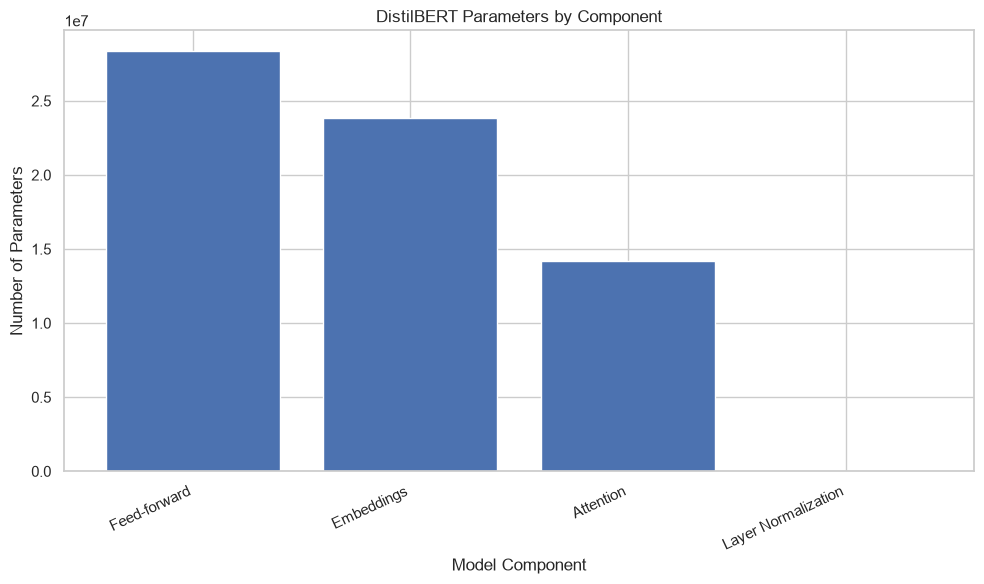

In [48]:

plt.figure(figsize=(10, 6))

plt.bar(
    parameter_summary["Component"],
    parameter_summary["Parameters"]
)

plt.title("DistilBERT Parameters by Component")
plt.xlabel("Model Component")
plt.ylabel("Number of Parameters")

plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.savefig(
    "plots/task4_parameter_counts.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


## Plot parameter percentages

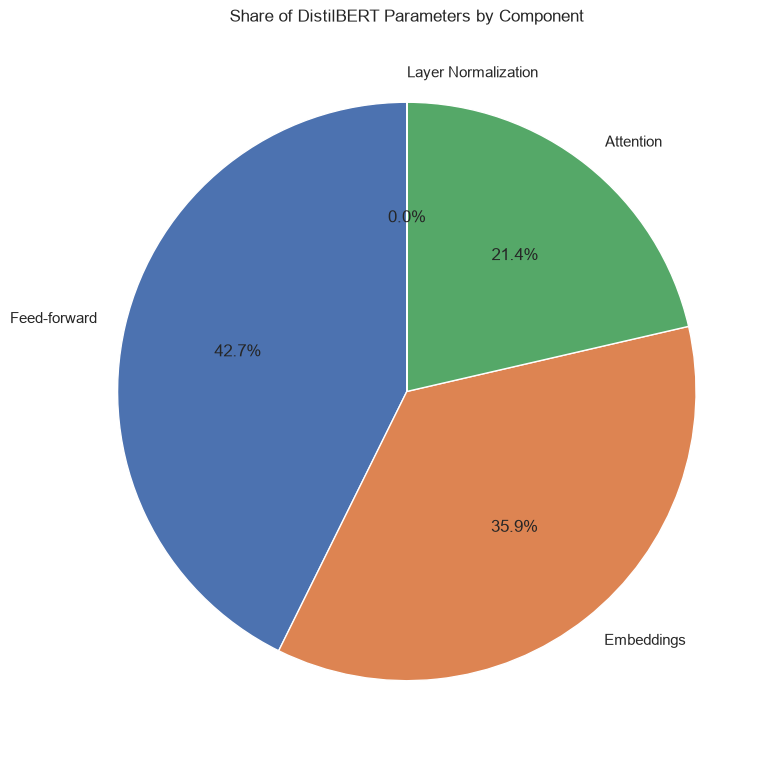

In [49]:

plt.figure(figsize=(8, 8))

plt.pie(
    parameter_summary["Parameters"],
    labels=parameter_summary["Component"],
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Share of DistilBERT Parameters by Component")
plt.tight_layout()
plt.savefig(
    "plots/task4_parameter_percentages.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


### Parameter Distribution Observations

The parameter count shows how the learned weights are distributed across the embedding, attention, feed-forward, and normalization components.

The feed-forward network can contain a substantial share of the model's parameters because it expands the hidden representation before projecting it back to the original hidden size. Attention also requires learned query, key, value, and output projection weights.

The exact counts and percentages should be reported from the executed notebook output. The grouping is based on parameter names, so the "Other" category may contain any parameters not matched by the chosen rules.


## Task 4.4 — Predict Masked Words with DistilBERT
DistilBERT can be used as a masked language model when loaded with the base model checkpoint distilbert-base-uncased. It uses context from both sides of a masked token to predict possible replacements.

## Load the fill-mask pipeline

In [50]:

from transformers import pipeline

fill_masker = pipeline(
    "fill-mask",
    model="distilbert-base-uncased",
    tokenizer="distilbert-base-uncased"
)

print("Masked language model loaded successfully.")


Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

Masked language model loaded successfully.


## Predict missing words in three sentences

In [51]:

masked_sentences = [
    "The animal did not cross the [MASK] because it was tired.",
    "Machine learning is a branch of [MASK].",
    "She opened the book and started to [MASK]."
]

for sentence in masked_sentences:
    print("\nSentence:", sentence)

    predictions = fill_masker(
        sentence,
        top_k=3
    )

    for rank, prediction in enumerate(predictions, start=1):
        print(
            f"{rank}. {prediction['token_str'].strip()} "
            f"| score={prediction['score']:.4f}"
        )



Sentence: The animal did not cross the [MASK] because it was tired.
1. threshold | score=0.0675
2. ground | score=0.0407
3. road | score=0.0406

Sentence: Machine learning is a branch of [MASK].
1. robotics | score=0.3732
2. mathematics | score=0.3196
3. neuroscience | score=0.0499

Sentence: She opened the book and started to [MASK].
1. read | score=0.5492
2. write | score=0.2515
3. chew | score=0.0085



### Masked Language Modeling Observations

The fill-mask pipeline replaces `[MASK]` with candidate tokens and assigns each candidate a score.

DistilBERT's encoder can use both preceding and following context to predict a masked token. For example, in a sentence containing a missing noun, words before and after the mask can both provide useful clues.

The top prediction is not guaranteed to be factually correct or the only grammatically valid choice. Interpret the candidates in the context of each sentence.


## Task 4.5 — Visualize Bidirectional Encoder Attention
## Extract the last-layer attention matrix

In [52]:

sentence = (
    "The animal did not cross the street "
    "because it was too tired."
)

inputs = tokenizer(
    sentence,
    return_tensors="pt"
)

model.eval()

with torch.no_grad():
    outputs = model(
        **inputs,
        output_attentions=True
    )

last_layer_attention = outputs.attentions[-1]

print("Last-layer attention shape:")
print(last_layer_attention.shape)

# Average over all attention heads.
mean_attention = (
    last_layer_attention[0]
    .mean(dim=0)
    .cpu()
    .numpy()
)

tokens = tokenizer.convert_ids_to_tokens(
    inputs["input_ids"][0]
)

print("\nTokens:")
print(tokens)

print("\nMean attention matrix shape:")
print(mean_attention.shape)


Last-layer attention shape:
torch.Size([1, 12, 15, 15])

Tokens:
['[CLS]', 'the', 'animal', 'did', 'not', 'cross', 'the', 'street', 'because', 'it', 'was', 'too', 'tired', '.', '[SEP]']

Mean attention matrix shape:
(15, 15)


## Plot the averaged attention matrix

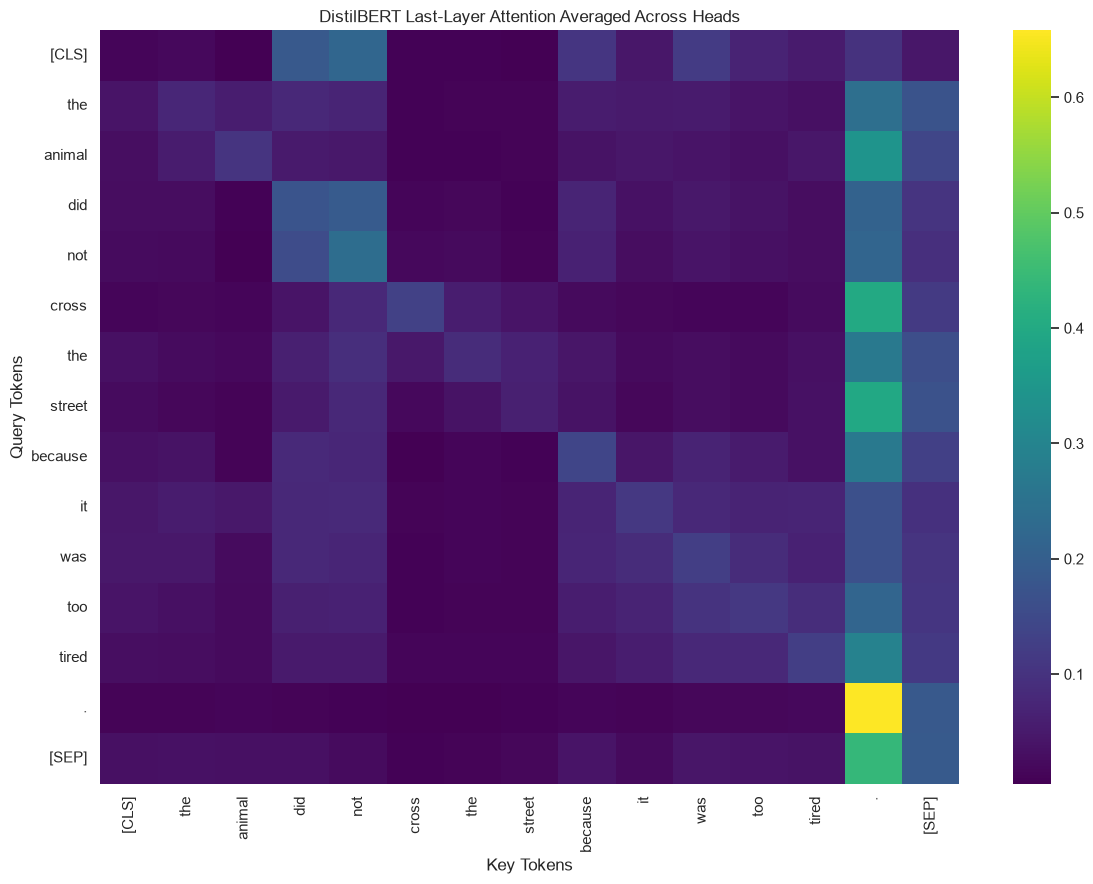

In [53]:

plt.figure(figsize=(12, 9))

sns.heatmap(
    mean_attention,
    xticklabels=tokens,
    yticklabels=tokens,
    cmap="viridis"
)

plt.title("DistilBERT Last-Layer Attention Averaged Across Heads")
plt.xlabel("Key Tokens")
plt.ylabel("Query Tokens")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig(
    "plots/task4_bidirectional_attention_matrix.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

## Check attention above and below the diagonal

In [54]:

sequence_length = mean_attention.shape[0]

upper_triangle = mean_attention[
    np.triu_indices(sequence_length, k=1)
]

lower_triangle = mean_attention[
    np.tril_indices(sequence_length, k=-1)
]

print(
    "Maximum attention above diagonal:",
    float(upper_triangle.max())
)

print(
    "Maximum attention below diagonal:",
    float(lower_triangle.max())
)

print(
    "Has positive attention above diagonal:",
    bool(np.any(upper_triangle > 0))
)

print(
    "Has positive attention below diagonal:",
    bool(np.any(lower_triangle > 0))
)


Maximum attention above diagonal: 0.3990788757801056
Maximum attention below diagonal: 0.4407411515712738
Has positive attention above diagonal: True
Has positive attention below diagonal: True



### Bidirectional vs Causal Attention

**Bidirectional encoder attention:** A token can attend to valid tokens on either side of its position. This supports contextual representations that use both left and right context.

**Causal decoder attention:** A token cannot attend to future positions. This prevents a language model from using future tokens when predicting the next token.

DistilBERT uses bidirectional encoder attention, whereas GPT-2 uses causal decoder attention.


## Task 4.6 — Implement a Causal Mask with NumPy
A causal mask prevents each token from attending to future tokens. The standard additive mask assigns negative infinity to the positions above the diagonal, and zero to positions on or below the diagonal.

## Create a causal mask for six tokens

In [55]:

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sequence_length = 6

causal_mask = np.triu(
    np.full(
        (sequence_length, sequence_length),
        -np.inf
    ),
    k=1
)

# Set diagonal and lower triangle to zero.
causal_mask = np.tril(
    np.zeros((sequence_length, sequence_length))
) + np.triu(
    np.full(
        (sequence_length, sequence_length),
        -np.inf
    ),
    k=1
)

print("Causal mask:")
print(causal_mask)


Causal mask:
[[  0. -inf -inf -inf -inf -inf]
 [  0.   0. -inf -inf -inf -inf]
 [  0.   0.   0. -inf -inf -inf]
 [  0.   0.   0.   0. -inf -inf]
 [  0.   0.   0.   0.   0. -inf]
 [  0.   0.   0.   0.   0.   0.]]


## Visualize the causal mask

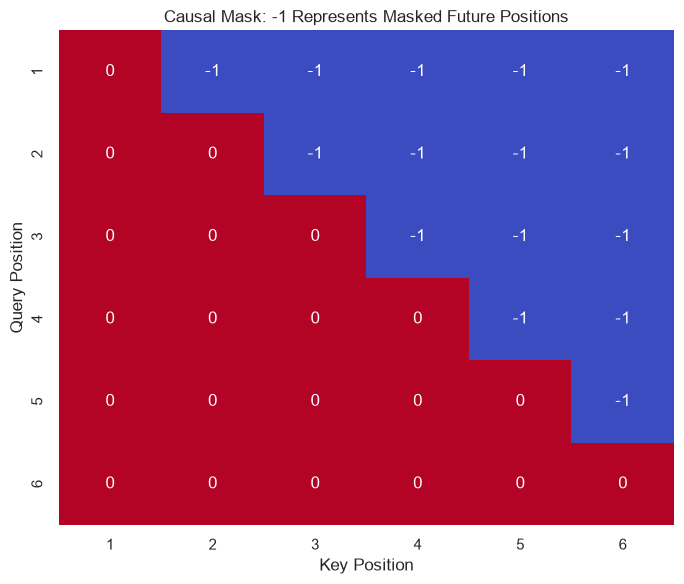

In [56]:

mask_for_plot = np.where(
    np.isneginf(causal_mask),
    -1,
    0
)

plt.figure(figsize=(7, 6))

sns.heatmap(
    mask_for_plot,
    annot=True,
    fmt="d",
    cmap="coolwarm",
    xticklabels=range(1, sequence_length + 1),
    yticklabels=range(1, sequence_length + 1),
    cbar=False
)

plt.title("Causal Mask: -1 Represents Masked Future Positions")
plt.xlabel("Key Position")
plt.ylabel("Query Position")
plt.tight_layout()
plt.savefig(
    "plots/task4_causal_mask.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

## Apply the mask before softmax

In [57]:

def stable_softmax(x, axis=-1):
    x = x - np.max(x, axis=axis, keepdims=True)
    exp_x = np.exp(x)
    return exp_x / np.sum(exp_x, axis=axis, keepdims=True)


np.random.seed(42)

# Simulated attention scores.
attention_scores = np.random.randn(
    sequence_length,
    sequence_length
)

masked_scores = attention_scores + causal_mask

causal_attention_weights = stable_softmax(
    masked_scores,
    axis=-1
)

print("Masked attention scores:")
print(masked_scores)

print("\nCausal attention weights:")
print(np.round(causal_attention_weights, 4))

print("\nSum of each row:")
print(causal_attention_weights.sum(axis=-1))


Masked attention scores:
[[ 0.49671415        -inf        -inf        -inf        -inf        -inf]
 [ 1.57921282  0.76743473        -inf        -inf        -inf        -inf]
 [ 0.24196227 -1.91328024 -1.72491783        -inf        -inf        -inf]
 [-0.90802408 -1.4123037   1.46564877 -0.2257763         -inf        -inf]
 [-0.54438272  0.11092259 -1.15099358  0.37569802 -0.60063869        -inf]
 [-0.60170661  1.85227818 -0.01349722 -1.05771093  0.82254491 -1.22084365]]

Causal attention weights:
[[1.     0.     0.     0.     0.     0.    ]
 [0.6925 0.3075 0.     0.     0.     0.    ]
 [0.7963 0.0923 0.1114 0.     0.     0.    ]
 [0.0698 0.0422 0.7498 0.1382 0.     0.    ]
 [0.1444 0.2781 0.0787 0.3623 0.1365 0.    ]
 [0.0506 0.5887 0.0911 0.0321 0.2102 0.0272]]

Sum of each row:
[1. 1. 1. 1. 1. 1.]


## Verify future-token attention is zero

In [58]:

future_attention = causal_attention_weights[
    np.triu_indices(sequence_length, k=1)
]

print(
    "Maximum attention assigned to future tokens:",
    float(future_attention.max())
)

print(
    "All future-token attention weights are zero:",
    bool(np.allclose(future_attention, 0.0))
)

print(
    "All row sums equal 1:",
    bool(
        np.allclose(
            causal_attention_weights.sum(axis=-1),
            1.0
        )
    )
)


Maximum attention assigned to future tokens: 0.0
All future-token attention weights are zero: True
All row sums equal 1: True



### Why Mask Before Softmax?

The mask is added to the attention scores before softmax. Adding negative infinity makes the corresponding softmax probability zero.

If future positions were set to zero only after softmax, the remaining probabilities would generally no longer sum to one unless they were normalized again.

The causal mask therefore prevents future information from contributing to the current token's attention distribution.


## Task 4.7 — Inspect Causal Attention in GPT-2
GPT-2 is a decoder-only language model. Its self-attention uses a causal mask so each position cannot attend to future tokens.

## Load pretrained GPT-2

In [59]:

from transformers import AutoTokenizer, AutoModelForCausalLM

gpt2_name = "gpt2"

gpt2_tokenizer = AutoTokenizer.from_pretrained(gpt2_name)

gpt2_model = AutoModelForCausalLM.from_pretrained(
    gpt2_name,
    attn_implementation="eager"
)

gpt2_model.eval()

print("Model:", gpt2_name)
print("Number of layers:", gpt2_model.config.n_layer)
print("Number of attention heads:", gpt2_model.config.n_head)
print("Hidden size:", gpt2_model.config.n_embd)


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Model: gpt2
Number of layers: 12
Number of attention heads: 12
Hidden size: 768


## Extract the last-layer attention weights

In [60]:

gpt_sentence = "Artificial intelligence can help people"

gpt_inputs = gpt2_tokenizer(
    gpt_sentence,
    return_tensors="pt"
)

with torch.no_grad():
    gpt_outputs = gpt2_model(
        **gpt_inputs,
        output_attentions=True
    )

gpt_attentions = gpt_outputs.attentions

print("Number of layers:", len(gpt_attentions))
print("Last-layer attention shape:", gpt_attentions[-1].shape)

gpt_tokens = gpt2_tokenizer.convert_ids_to_tokens(
    gpt_inputs["input_ids"][0]
)

print("Tokens:", gpt_tokens)


Number of layers: 12
Last-layer attention shape: torch.Size([1, 12, 6, 6])
Tokens: ['Art', 'ificial', 'Ġintelligence', 'Ġcan', 'Ġhelp', 'Ġpeople']


## Plot one attention head

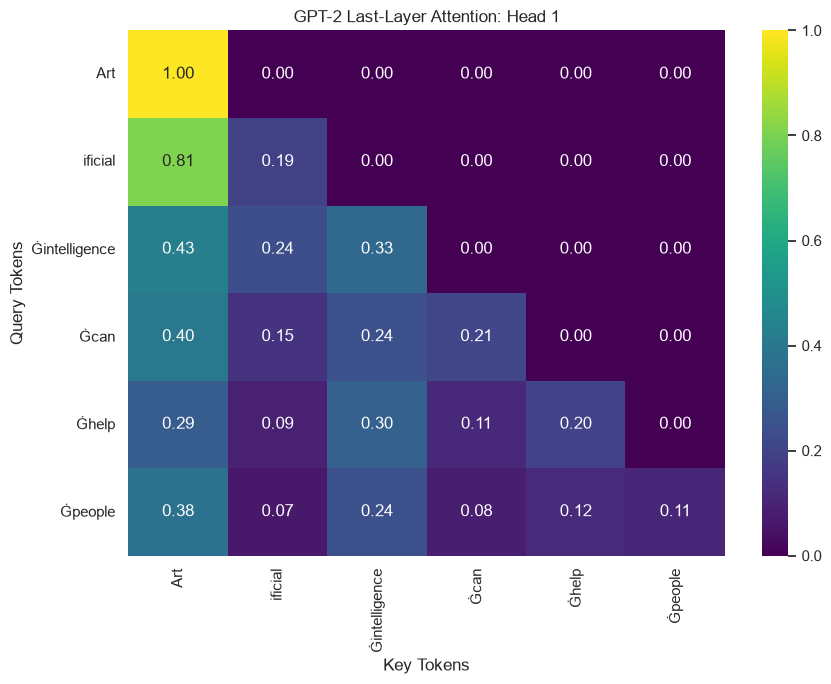

In [61]:

# Last layer, first item in batch, first attention head.
gpt_attention_head = (
    gpt_attentions[-1][0, 0]
    .detach()
    .cpu()
    .numpy()
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    gpt_attention_head,
    annot=True,
    fmt=".2f",
    xticklabels=gpt_tokens,
    yticklabels=gpt_tokens,
    cmap="viridis"
)

plt.title("GPT-2 Last-Layer Attention: Head 1")
plt.xlabel("Key Tokens")
plt.ylabel("Query Tokens")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig(
    "plots/task4_gpt2_causal_attention_head.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

## Verify future positions are masked

In [62]:

future_values = gpt_attention_head[
    np.triu_indices(
        gpt_attention_head.shape[0],
        k=1
    )
]

print(
    "Maximum future-position attention:",
    float(future_values.max()) if future_values.size else 0.0
)

print(
    "Future attention is approximately zero:",
    bool(np.allclose(future_values, 0.0, atol=1e-6))
)


Maximum future-position attention: 0.0
Future attention is approximately zero: True


## Task 4.8 — Understand Padding Masks
A padding mask prevents attention from being assigned to padding tokens. A causal mask prevents attention to future positions. They solve different problems.

We'll batch two sentences of different lengths and use padding to make their tensor lengths equal.
## Tokenize two sentences with padding

In [63]:

distil_sentences = [
    "Transformers learn patterns from language.",
    "Transformers learn patterns."
]

batch_inputs = tokenizer(
    distil_sentences,
    padding=True,
    truncation=True,
    return_tensors="pt"
)

print("Input IDs:")
print(batch_inputs["input_ids"])

print("\nAttention mask:")
print(batch_inputs["attention_mask"])

print("\nTokens for each sentence:")

for row in batch_inputs["input_ids"]:
    print(tokenizer.convert_ids_to_tokens(row))


Input IDs:
tensor([[  101, 19081,  4553,  7060,  2013,  2653,  1012,   102],
        [  101, 19081,  4553,  7060,  1012,   102,     0,     0]])

Attention mask:
tensor([[1, 1, 1, 1, 1, 1, 1, 1],
        [1, 1, 1, 1, 1, 1, 0, 0]])

Tokens for each sentence:
['[CLS]', 'transformers', 'learn', 'patterns', 'from', 'language', '.', '[SEP]']
['[CLS]', 'transformers', 'learn', 'patterns', '.', '[SEP]', '[PAD]', '[PAD]']


## Extract attention for the padded batch

In [64]:

with torch.no_grad():
    batch_outputs = model(
        **batch_inputs,
        output_attentions=True
    )

batch_last_attention = batch_outputs.attentions[-1]

print(
    "Last-layer attention shape:",
    batch_last_attention.shape
)


Last-layer attention shape: torch.Size([2, 12, 8, 8])


## Check attention directed toward padding keys

In [65]:

second_attention_mask = batch_inputs["attention_mask"][1]

padding_positions = (
    second_attention_mask == 0
).nonzero(as_tuple=True)[0]

print("Padding token positions:", padding_positions.tolist())

if len(padding_positions) > 0:
    second_sentence_attention = batch_last_attention[1]

    # Shape before selection: (heads, query tokens, key tokens).
    padding_attention = second_sentence_attention[
        :, :, padding_positions
    ]

    print(
        "Maximum attention weight assigned to padding keys:",
        float(padding_attention.max())
    )

    print(
        "Mean attention weight assigned to padding keys:",
        float(padding_attention.mean())
    )
else:
    print(
        "No padding was added. Try sentences with a larger length difference."
    )


Padding token positions: [6, 7]
Maximum attention weight assigned to padding keys: 0.0
Mean attention weight assigned to padding keys: 0.0


## Compare padding and causal masks


### Padding Mask vs Causal Mask

| Feature | Padding Mask | Causal Mask |
|---|---|---|
| Main purpose | Ignore padding tokens | Block future tokens |
| Common use | Encoder and decoder inputs with padding | Autoregressive decoder attention |
| Restricted positions | Positions representing padding | Positions later than the current query |
| DistilBERT encoder | Used when inputs contain padding | Not normally used for standard encoder self-attention |
| GPT-2 | May also use a padding mask when padding is present | Used to prevent access to future tokens |

A padding mask and a causal mask are not interchangeable. In some architectures, both restrictions can be applied simultaneously.


## Task 4.9 — Final Summary

## Task 4: Final Summary

In this task, I explored Transformer encoder architecture and the differences between bidirectional and causal attention.

### Concepts Covered

1. Inspected DistilBERT's embedding, attention, feed-forward, and normalization modules.
2. Counted parameters by model component and visualized their distribution.
3. Used a pretrained masked language model to predict missing words.
4. Extracted and visualized DistilBERT's bidirectional attention.
5. Implemented a causal mask using NumPy and verified that future-token attention weights become zero.
6. Loaded pretrained GPT-2 and inspected its causal attention.
7. Examined padding masks using a batch of sentences with different lengths.
8. Compared padding masks with causal masks.

### Conclusion

Transformer encoders such as DistilBERT use bidirectional self-attention to create contextual representations. Decoder-only models such as GPT-2 use causal attention to prevent future-token information from influencing next-token prediction. Padding masks separately prevent attention to padded input positions.


## Task 5.1 — Understand the Transformer Decoder

# Task 5: Transformer Decoder, Cross-Attention, and Inference

## Objectives
1. Understand the Transformer decoder architecture.
2. Explain cross-attention between encoder and decoder.
3. Perform translation and summarization using pretrained T5.
4. Visualize cross-attention weights.
5. Implement greedy text generation with GPT-2.
6. Compare greedy search, beam search, and sampling.
7. Measure the effect of the key-value cache.
8. Compare encoder-only, decoder-only, and encoder-decoder models.



## 5.1 Transformer Decoder Architecture

In the original encoder-decoder Transformer, each decoder block contains:

1. Masked multi-head self-attention.
2. A residual connection and Layer Normalization.
3. Cross-attention over the encoder output.
4. Another residual connection and Layer Normalization.
5. A feed-forward neural network.
6. A final residual connection and Layer Normalization.

The decoder's masked self-attention prevents each output position from attending to future output tokens. Cross-attention allows the decoder to use information from the encoder output.

After the decoder produces hidden representations, a linear projection and softmax produce a probability distribution over possible next tokens.

### Model families

- **DistilBERT:** encoder-only; commonly used for classification and contextual representations.
- **GPT-2:** decoder-only; commonly used for autoregressive text generation.
- **T5:** encoder-decoder; supports text-to-text tasks such as translation and summarization.

These model families have different architectures, so not every model contains every component of the original Transformer.


## Task 5.2 — Understand Cross-Attention
In cross-attention, the query vectors come from the decoder, while the key and value vectors come from the encoder output.
\[
Q = H_{\text{decoder}}W^Q
\]

\[
K = H_{\text{encoder}}W^K,\quad
V = H_{\text{encoder}}W^V
\]

\[
\operatorname{Attention}(Q,K,V)=
\operatorname{softmax}\left(\frac{QK^\top}{\sqrt{d_k}}\right)V
\]

This enables each decoder position to retrieve relevant information from the input sequence.


### Self-Attention vs Cross-Attention

**Self-attention:** Queries, keys, and values are derived from the same sequence representation.

**Cross-attention:** Queries come from one sequence, typically the decoder, while keys and values come from another sequence, typically the encoder output.

Luong attention, implemented in Task 2, is a form of attention that scores decoder states against encoder states. Transformer cross-attention uses learned projections and scaled dot-product attention, usually across multiple heads.


## Task 5.3 — Perform Translation and Summarization Using T5
T5 is a text-to-text model. It uses a task prefix to indicate what operation it should perform.

For example:
- Translation: translate English to French: ...
- Summarization: summarize: ...

## Load the pretrained T5 model

In [66]:

import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time

from transformers import (
    AutoTokenizer,
    AutoModelForSeq2SeqLM,
    pipeline
)

t5_name = "t5-small"

t5_tokenizer = AutoTokenizer.from_pretrained(t5_name)

t5_model = AutoModelForSeq2SeqLM.from_pretrained(
    t5_name,
    attn_implementation="eager"
)

t5_model.eval()

print("Model:", t5_name)
print("Model class:", t5_model.__class__.__name__)
print("Encoder layers:", t5_model.config.num_layers)
print("Decoder layers:", t5_model.config.num_decoder_layers)
print("Attention heads:", t5_model.config.num_heads)


Loading weights:   0%|          | 0/131 [00:00<?, ?it/s]

Model: t5-small
Model class: T5ForConditionalGeneration
Encoder layers: 6
Decoder layers: 6
Attention heads: 8


## Translate three English sentences into French

In [67]:

import torch
import pandas as pd

# Put the T5 model in evaluation mode
t5_model.eval()

# English sentences to translate into French
english_sentences = [
    "The house is small.",
    "Machine learning helps us discover patterns in data.",
    "Artificial intelligence is changing the way people work."
]

translation_results = []

# Translate each sentence using T5 directly
for sentence in english_sentences:

    # T5 requires a task prefix for translation
    input_text = "translate English to French: " + sentence

    # Tokenize the input
    inputs = t5_tokenizer(
        input_text,
        return_tensors="pt",
        truncation=True,
        max_length=512
    )

    # Move input tensors to the model's device
    inputs = {
        key: value.to(next(t5_model.parameters()).device)
        for key, value in inputs.items()
    }

    # Generate the French translation
    with torch.no_grad():
        output_ids = t5_model.generate(
            **inputs,
            max_new_tokens=60,
            num_beams=4,
            early_stopping=True
        )

    # Convert generated token IDs into text
    translated_text = t5_tokenizer.decode(
        output_ids[0],
        skip_special_tokens=True
    )

    translation_results.append({
        "English Sentence": sentence,
        "French Translation": translated_text
    })

# Display the results
translation_df = pd.DataFrame(translation_results)
display(translation_df)


,English Sentence,French Translation
0,The house is small.,La maison est petite.
1,Machine learning helps us discover patterns in...,L'apprentissage en machine nous aide à découvr...
2,Artificial intelligence is changing the way pe...,L'intelligence artificielle change la façon do...



### Translation observations

T5-small is an encoder-decoder Transformer. The encoder represents the English input, and the decoder generates the French output one token at a time.

The translation quality can vary depending on sentence complexity and the model's learned patterns. The output should be checked for grammatical correctness and preservation of meaning.


## Summarize a passage

In [68]:

passage = """
Artificial intelligence and machine learning are increasingly used
in healthcare, education, finance, transportation, and manufacturing.
These technologies help organizations analyze large amounts of data,
automate repetitive tasks, and make better decisions. Deep learning
models can recognize images, understand language, and generate content.
However, AI systems may also introduce challenges related to bias,
privacy, transparency, reliability, and human oversight.
"""

# Prepare the summarization prompt
summary_prompt = "summarize: " + passage.strip()

# Tokenize the input passage
inputs = t5_tokenizer(
    summary_prompt,
    return_tensors="pt",
    truncation=True,
    max_length=512
)

# Move input tensors to the T5 model's device
device = next(t5_model.parameters()).device
inputs = {key: value.to(device) for key, value in inputs.items()}

# Generate the summary
t5_model.eval()

with torch.no_grad():
    summary_ids = t5_model.generate(
        **inputs,
        max_new_tokens=60,
        num_beams=4,
        early_stopping=True
    )

# Convert generated tokens into readable text
summary_result = t5_tokenizer.decode(
    summary_ids[0],
    skip_special_tokens=True
)

print("Original passage:\n")
print(passage)

print("\nGenerated summary:\n")
print(summary_result)


Original passage:


Artificial intelligence and machine learning are increasingly used
in healthcare, education, finance, transportation, and manufacturing.
These technologies help organizations analyze large amounts of data,
automate repetitive tasks, and make better decisions. Deep learning
models can recognize images, understand language, and generate content.
However, AI systems may also introduce challenges related to bias,
privacy, transparency, reliability, and human oversight.


Generated summary:

artificial intelligence and machine learning are increasingly used in healthcare, education, finance, transportation, and manufacturing. AI systems may also introduce challenges related to bias, privacy, transparency, reliability, and human oversight.



### Summarization observations

T5 receives the instruction `summarize:` together with the source paragraph. It generates a shorter text intended to retain the main ideas.

The word-count reduction measures the change in length, not the accuracy of the summary. A short summary can still omit important information or introduce an error, so the generated text should be compared with the original passage.


## Task 5.4 — Extract and Visualize T5 Cross-Attention
Now we will inspect cross-attention for the sentence:

The house is small.

The encoder processes the English input. The decoder generates French output and uses cross-attention to retrieve information from the encoder representation.
## Tokenize the input and expected target

In [69]:

source_sentence = "The house is small."
target_sentence = "La maison est petite."

source_prompt = "translate English to French: " + source_sentence

encoder_inputs = t5_tokenizer(
    source_prompt,
    return_tensors="pt"
)

target_inputs = t5_tokenizer(
    target_sentence,
    return_tensors="pt"
)

source_tokens = t5_tokenizer.convert_ids_to_tokens(
    encoder_inputs["input_ids"][0]
)

target_tokens = t5_tokenizer.convert_ids_to_tokens(
    target_inputs["input_ids"][0]
)

print("Source tokens:")
print(source_tokens)

print("\nTarget tokens:")
print(target_tokens)


Source tokens:
['▁translate', '▁English', '▁to', '▁French', ':', '▁The', '▁house', '▁is', '▁small', '.', '</s>']

Target tokens:
['▁La', '▁maison', '▁est', '▁petite', '.', '</s>']


## Run T5 with labels and request attention weights

In [70]:

with torch.no_grad():
    t5_outputs = t5_model(
        input_ids=encoder_inputs["input_ids"],
        attention_mask=encoder_inputs["attention_mask"],
        labels=target_inputs["input_ids"],
        output_attentions=True,
        return_dict=True
    )

print("Loss:", float(t5_outputs.loss))
print("Number of cross-attention layers:", len(t5_outputs.cross_attentions))

last_cross_attention = t5_outputs.cross_attentions[-1]

print(
    "Last decoder layer cross-attention shape:",
    last_cross_attention.shape
)


Loss: 0.15406198799610138
Number of cross-attention layers: 6
Last decoder layer cross-attention shape: torch.Size([1, 8, 6, 11])


What the output means:

The cross-attention tensor normally has the shape:

(batch_size, number_of_heads, target_length, source_length)

The target length corresponds to decoder positions, and the source length corresponds to encoder input positions.

T5 shifts decoder inputs internally when training-style labels are supplied. The displayed target token sequence is therefore used for supervision, and the cross-attention query positions correspond to decoder positions rather than being a direct word-to-word alignment.

## Average cross-attention across heads

In [71]:

cross_attention_matrix = (
    last_cross_attention[0]
    .mean(dim=0)
    .detach()
    .cpu()
    .numpy()
)

print("Mean cross-attention matrix shape:")
print(cross_attention_matrix.shape)

print("\nTarget token count:", len(target_tokens))
print("Source token count:", len(source_tokens))


Mean cross-attention matrix shape:
(6, 11)

Target token count: 6
Source token count: 11


## Plot the cross-attention matrix

c:\Users\hp\AppData\Local\Programs\Python\Python311\Lib\site-packages\seaborn\utils.py:61: UserWarning: Glyph 9601 (\N{LOWER ONE EIGHTH BLOCK}) missing from font(s) Arial.
  fig.canvas.draw()
C:\Users\hp\AppData\Local\Temp\ipykernel_11392\1185505153.py:16: UserWarning: Glyph 9601 (\N{LOWER ONE EIGHTH BLOCK}) missing from font(s) Arial.
  plt.savefig(
c:\Users\hp\AppData\Local\Programs\Python\Python311\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 9601 (\N{LOWER ONE EIGHTH BLOCK}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


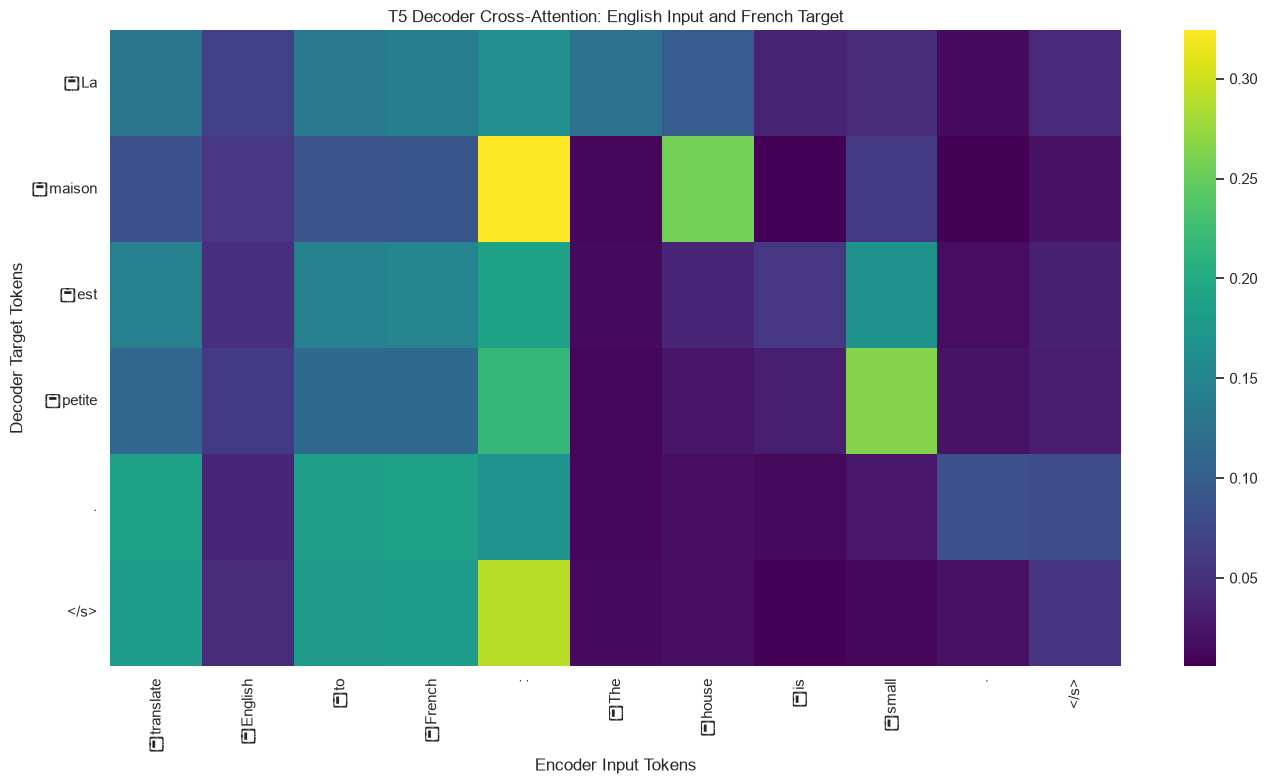

In [72]:

plt.figure(figsize=(14, 8))

sns.heatmap(
    cross_attention_matrix,
    xticklabels=source_tokens,
    yticklabels=target_tokens,
    cmap="viridis"
)

plt.title("T5 Decoder Cross-Attention: English Input and French Target")
plt.xlabel("Encoder Input Tokens")
plt.ylabel("Decoder Target Tokens")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig(
    "plots/task5_t5_cross_attention_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


### Cross-Attention Observations

The heatmap displays how decoder positions distribute their cross-attention weights over encoder input tokens.

Different decoder positions may attend to different parts of the input. This helps the decoder condition its output on the source representation.

However, attention weights should not be treated as a guaranteed word-alignment map. T5 may split words into subword tokens, and the input includes the translation task prefix and special tokens. Therefore, any apparent alignment should be described cautiously.


## Task 5.5 — Implement Greedy Text Generation with GPT-2
GPT-2 predicts the next token from the tokens generated so far. Greedy decoding chooses the token with the highest probability at each step.
\[
\hat{y}_t=\arg\max_y P(y\mid y_1,\ldots,y_{t-1},x)
\]

We will first implement a manual greedy-generation loop, then compare it with model.generate().
## Load GPT-2

In [73]:

from transformers import AutoTokenizer, AutoModelForCausalLM

gpt2_name = "gpt2"

gpt2_tokenizer = AutoTokenizer.from_pretrained(gpt2_name)

gpt2_model = AutoModelForCausalLM.from_pretrained(
    gpt2_name,
    attn_implementation="eager"
)

gpt2_model.eval()

# GPT-2 does not define a separate padding token by default.
gpt2_tokenizer.pad_token = gpt2_tokenizer.eos_token

print("GPT-2 loaded successfully.")


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

GPT-2 loaded successfully.


## Generate 20 tokens manually

In [74]:

def manual_greedy_generation(model, tokenizer, prompt, max_new_tokens=20):
    model.eval()

    input_ids = tokenizer(
        prompt,
        return_tensors="pt"
    )["input_ids"]

    generated_ids = input_ids.clone()
    past_key_values = None

    with torch.no_grad():
        for _ in range(max_new_tokens):
            if past_key_values is None:
                model_inputs = {
                    "input_ids": generated_ids,
                    "use_cache": True
                }
            else:
                model_inputs = {
                    "input_ids": generated_ids[:, -1:],
                    "past_key_values": past_key_values,
                    "use_cache": True
                }

            outputs = model(**model_inputs)

            next_token_logits = outputs.logits[:, -1, :]
            next_token = torch.argmax(
                next_token_logits,
                dim=-1,
                keepdim=True
            )

            generated_ids = torch.cat(
                [generated_ids, next_token],
                dim=-1
            )

            past_key_values = outputs.past_key_values

    return tokenizer.decode(
        generated_ids[0],
        skip_special_tokens=True
    )


prompt = "Artificial intelligence will"

manual_output = manual_greedy_generation(
    gpt2_model,
    gpt2_tokenizer,
    prompt,
    max_new_tokens=20
)

print("Prompt:", prompt)
print("\nManual greedy output:\n")
print(manual_output)


Prompt: Artificial intelligence will

Manual greedy output:

Artificial intelligence will be able to do things like search for and find people, and to do things like find out who


## Compare against generate()

In [75]:

prompt = "Artificial intelligence will"

prompt_ids = gpt2_tokenizer(
    prompt,
    return_tensors="pt"
)["input_ids"]

with torch.no_grad():
    generated_ids = gpt2_model.generate(
        input_ids=prompt_ids,
        max_new_tokens=20,
        do_sample=False,
        num_beams=1,
        use_cache=True,
        pad_token_id=gpt2_tokenizer.eos_token_id
    )

generate_output = gpt2_tokenizer.decode(
    generated_ids[0],
    skip_special_tokens=True
)

print("Manual generation:\n")
print(manual_output)

print("\nUsing model.generate():\n")
print(generate_output)

print(
    "\nOutputs match:",
    manual_output == generate_output
)


Manual generation:

Artificial intelligence will be able to do things like search for and find people, and to do things like find out who

Using model.generate():

Artificial intelligence will be able to do things like search for and find people, and to do things like find out who

Outputs match: True



### Greedy Generation Observations

The manual loop selects the highest-logit token at each step and appends it to the sequence. With key-value caching enabled, the model reuses previously computed attention keys and values rather than recomputing the entire prefix for every new token.

Greedy decoding is deterministic for a fixed model and input under the same inference settings. However, choosing the highest-probability token at each step does not guarantee the most coherent or factually accurate complete response.


## Task 5.6 — Compare Greedy Search, Beam Search, and Sampling
Different decoding strategies can produce different continuations from the same prompt.
- Greedy decoding: chooses the highest-scoring next token at each step.
- Beam search: tracks several candidate sequences.
- Temperature sampling: adjusts the sharpness of the probability distribution before sampling.
- Top-k sampling: samples from a restricted set of the top k candidate tokens.
- Top-p sampling: samples from a probability-ranked set whose cumulative probability reaches the specified threshold.
## Generate text with different decoding strategies

In [76]:

generation_prompt = "The future of artificial intelligence"

generation_input_ids = gpt2_tokenizer(
    generation_prompt,
    return_tensors="pt"
)["input_ids"]


def decode_generation(output_ids):
    return gpt2_tokenizer.decode(
        output_ids[0],
        skip_special_tokens=True
    )


generation_results = {}


# 1. Greedy decoding
with torch.no_grad():
    output = gpt2_model.generate(
        generation_input_ids,
        max_new_tokens=40,
        do_sample=False,
        num_beams=1,
        use_cache=True,
        pad_token_id=gpt2_tokenizer.eos_token_id
    )

generation_results["Greedy"] = decode_generation(output)


# 2. Beam search
with torch.no_grad():
    output = gpt2_model.generate(
        generation_input_ids,
        max_new_tokens=40,
        do_sample=False,
        num_beams=5,
        early_stopping=True,
        use_cache=True,
        pad_token_id=gpt2_tokenizer.eos_token_id
    )

generation_results["Beam search (5 beams)"] = decode_generation(output)


# 3. Temperature sampling
for temperature, seed in [(0.7, 42), (1.5, 123)]:
    torch.manual_seed(seed)

    with torch.no_grad():
        output = gpt2_model.generate(
            generation_input_ids,
            max_new_tokens=40,
            do_sample=True,
            temperature=temperature,
            use_cache=True,
            pad_token_id=gpt2_tokenizer.eos_token_id
        )

    generation_results[f"Temperature {temperature}"] = decode_generation(output)


# 4. Top-k sampling
torch.manual_seed(42)

with torch.no_grad():
    output = gpt2_model.generate(
        generation_input_ids,
        max_new_tokens=40,
        do_sample=True,
        top_k=50,
        use_cache=True,
        pad_token_id=gpt2_tokenizer.eos_token_id
    )

generation_results["Top-k (50)"] = decode_generation(output)


# 5. Top-p sampling
torch.manual_seed(42)

with torch.no_grad():
    output = gpt2_model.generate(
        generation_input_ids,
        max_new_tokens=40,
        do_sample=True,
        top_p=0.9,
        use_cache=True,
        pad_token_id=gpt2_tokenizer.eos_token_id
    )

generation_results["Top-p (0.9)"] = decode_generation(output)


for strategy, text in generation_results.items():
    print("=" * 80)
    print(strategy)
    print("-" * 80)
    print(text)
    print()


Greedy
--------------------------------------------------------------------------------
The future of artificial intelligence is uncertain.

"We're not sure what the future will look like," said Dr. Michael S. Schoenfeld, a professor of computer science at the University of California, Berkeley.

Beam search (5 beams)
--------------------------------------------------------------------------------
The future of artificial intelligence is in the hands of the next generation of scientists and engineers.

The future of artificial intelligence is in the hands of the next generation of scientists and engineers.

The future of artificial intelligence

Temperature 0.7
--------------------------------------------------------------------------------
The future of artificial intelligence is bound to be bright.

A new report from the Center for Computer and Information Sciences (CCIS), a nonprofit think tank that advocates for privacy and safety in the Internet, is raising questions

Temperature 

## Store the outputs in a comparison table

In [77]:

generation_comparison = pd.DataFrame([
    {
        "Strategy": strategy,
        "Generated Text": text
    }
    for strategy, text in generation_results.items()
])

print(generation_comparison.to_string(index=False))


             Strategy                                                                                                                                                                                                                                                  Generated Text
               Greedy                                              The future of artificial intelligence is uncertain.\n\n"We're not sure what the future will look like," said Dr. Michael S. Schoenfeld, a professor of computer science at the University of California, Berkeley.
Beam search (5 beams) The future of artificial intelligence is in the hands of the next generation of scientists and engineers.\n\nThe future of artificial intelligence is in the hands of the next generation of scientists and engineers.\n\nThe future of artificial intelligence
      Temperature 0.7                   The future of artificial intelligence is bound to be bright.\n\nA new report from the Center for Computer and Information Scie


### Decoding Strategy Observations

Greedy decoding is deterministic under the same settings and tends to choose locally high-probability tokens. Beam search compares multiple candidate sequences and can produce a different continuation, although it does not guarantee factual correctness.

Sampling introduces variability. Lower temperature generally concentrates probability on higher-scoring tokens, while higher temperature generally produces a more varied distribution. Top-k and top-p limit the candidate tokens available during sampling in different ways.

The actual output depends on the prompt, checkpoint, tokenizer, decoding settings, and random seed. Compare the generated text from the notebook rather than assuming one method always produces the best output.


## Task 5.7 — Measure the Effect of the Key-Value Cache
During autoregressive generation, the model repeatedly predicts one new token at a time.

With use_cache=True, GPT-2 retains key and value tensors from previous tokens. With use_cache=False, the model recomputes attention over the growing prefix on each generation step.

The cache can reduce repeated computation, particularly for longer sequences, at the cost of additional memory.
## Benchmark generation with and without caching

In [78]:

import time
import pandas as pd
import torch

benchmark_prompt = (
    "Artificial intelligence and machine learning "
    "are important technologies because"
)

benchmark_inputs = gpt2_tokenizer(
    benchmark_prompt,
    return_tensors="pt"
)

def benchmark_generation(use_cache, repetitions=3):
    elapsed_times = []

    for run_number in range(repetitions):
        start_time = time.perf_counter()

        with torch.no_grad():
            output_ids = gpt2_model.generate(
                **benchmark_inputs,
                max_new_tokens=100,
                do_sample=False,
                num_beams=1,
                use_cache=use_cache,
                pad_token_id=gpt2_tokenizer.eos_token_id
            )

        elapsed = time.perf_counter() - start_time
        elapsed_times.append(elapsed)

        print(
            f"use_cache={use_cache}, "
            f"run={run_number + 1}, "
            f"time={elapsed:.3f} seconds, "
            f"output_tokens={output_ids.shape[1] - benchmark_inputs['input_ids'].shape[1]}"
        )

    return elapsed_times


print("Benchmark with cache:")
times_with_cache = benchmark_generation(
    use_cache=True,
    repetitions=3
)

print("\nBenchmark without cache:")
times_without_cache = benchmark_generation(
    use_cache=False,
    repetitions=3
)


Benchmark with cache:
use_cache=True, run=1, time=4.449 seconds, output_tokens=100
use_cache=True, run=2, time=4.713 seconds, output_tokens=100
use_cache=True, run=3, time=4.587 seconds, output_tokens=100

Benchmark without cache:
use_cache=False, run=1, time=11.834 seconds, output_tokens=100
use_cache=False, run=2, time=11.890 seconds, output_tokens=100
use_cache=False, run=3, time=12.173 seconds, output_tokens=100


## Summarize timing results

In [79]:

cache_results = pd.DataFrame([
    {
        "Configuration": "Cache enabled",
        "Mean time (seconds)": np.mean(times_with_cache),
        "Standard deviation (seconds)": np.std(times_with_cache)
    },
    {
        "Configuration": "Cache disabled",
        "Mean time (seconds)": np.mean(times_without_cache),
        "Standard deviation (seconds)": np.std(times_without_cache)
    }
])

print(cache_results.to_string(index=False))

mean_with_cache = np.mean(times_with_cache)
mean_without_cache = np.mean(times_without_cache)

if mean_with_cache > 0:
    print(
        "\nNo-cache / cache time ratio:",
        round(mean_without_cache / mean_with_cache, 3)
    )

    print(
        "Relative time reduction with cache:",
        f"{(1 - mean_with_cache / mean_without_cache) * 100:.2f}%"
        if mean_without_cache > 0
        else "Not available"
    )


 Configuration  Mean time (seconds)  Standard deviation (seconds)
 Cache enabled             4.583170                      0.107898
Cache disabled            11.965614                      0.148195

No-cache / cache time ratio: 2.611
Relative time reduction with cache: 61.70%


## Plot the benchmark

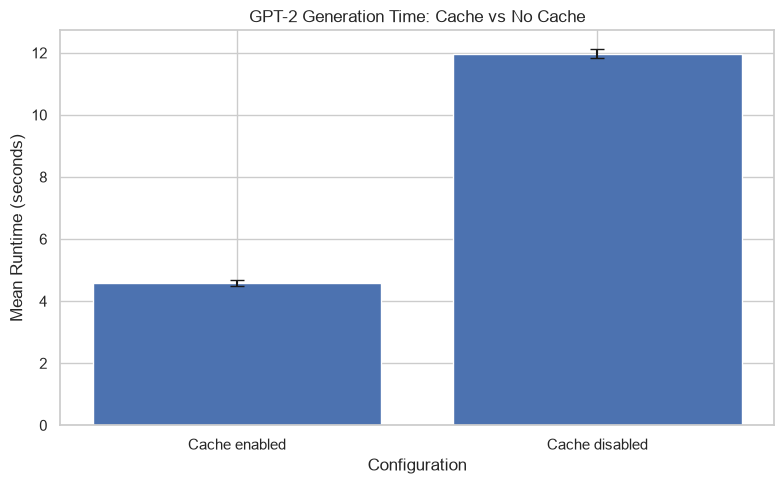

In [80]:

plt.figure(figsize=(8, 5))

plt.bar(
    cache_results["Configuration"],
    cache_results["Mean time (seconds)"],
    yerr=cache_results["Standard deviation (seconds)"],
    capsize=5
)

plt.title("GPT-2 Generation Time: Cache vs No Cache")
plt.ylabel("Mean Runtime (seconds)")
plt.xlabel("Configuration")
plt.tight_layout()
plt.savefig(
    "plots/task5_kv_cache_benchmark.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


### Key-Value Cache Observations

The key-value cache stores attention keys and values from previously processed tokens so they can be reused during autoregressive generation.

Caching can reduce repeated computation and improve generation speed, especially as the sequence grows. It also requires additional memory to store cached tensors.

The measured speedup depends on hardware, sequence length, model implementation, and runtime overhead. Report the actual timing values from this experiment. If the cache-enabled run is not faster on your computer, report that result rather than assuming a speedup.


## Task 5.8 — Compare the Three Transformer Model Families

## Task 5: Comparison of Transformer Model Families

| Feature | DistilBERT | GPT-2 | T5 |
|---|---|---|---|
| Architecture | Encoder-only | Decoder-only | Encoder-decoder |
| Main attention pattern | Bidirectional self-attention | Causal self-attention | Encoder self-attention, decoder causal self-attention, and cross-attention |
| Can use both left and right input context? | Yes, within the input sequence | Not for a given next-token prediction | Encoder can use both directions over its input |
| Text generation | Not its primary standard use | Autoregressive generation | Conditional text-to-text generation |
| Common applications | Classification, feature extraction | Text continuation and generation | Translation, summarization, and other text-to-text tasks |
| Example checkpoint in this project | `distilbert-base-uncased-finetuned-sst-2-english` | `gpt2` | `t5-small` |

These are typical uses of the model families, not exclusive restrictions. Actual capabilities depend on the checkpoint, task, and inference setup.



## Task 5: Final Summary

In this task, I explored decoder architecture, cross-attention, and pretrained Transformer inference.

### Concepts and Practical Work

1. Studied masked self-attention, cross-attention, residual connections, Layer Normalization, and feed-forward layers in the original Transformer decoder.
2. Used pretrained T5 to translate English sentences into French.
3. Summarized a passage and compared the original and summary word counts.
4. Extracted T5 cross-attention weights and visualized them using a heatmap.
5. Implemented manual greedy generation with GPT-2 and compared it with `generate()`.
6. Compared greedy decoding, beam search, temperature sampling, top-k sampling, and top-p sampling.
7. Benchmarked generation with and without the key-value cache.
8. Compared encoder-only, decoder-only, and encoder-decoder architectures.

### Conclusion

Transformer inference depends on the model architecture and decoding strategy. Encoder-decoder models such as T5 condition generated text on an input sequence through cross-attention. Decoder-only models such as GPT-2 generate autoregressively using causal attention. The key-value cache can reduce repeated computation during generation, while different decoding methods affect the generated output.

All experiments in this task use pretrained models without fine-tuning.



# Task 6: Evaluation, Performance Analysis, and Mini Text Toolkit

## Objectives
1. Evaluate a pretrained sentiment model on IMDB reviews.
2. Compare sentiment performance at different input lengths.
3. Measure model inference time at different sequence lengths.
4. Examine factual reliability in GPT-2 generations.
5. Build a text toolkit using sentiment analysis, summarization, and translation.
6. Reflect on Transformer capabilities and limitations.


## Task 6.1 — Evaluate DistilBERT on IMDB Reviews
We will evaluate distilbert-base-uncased-finetuned-sst-2-english on 200 IMDB test reviews.

Important: this checkpoint was fine-tuned for the SST-2 sentiment dataset, not the IMDB dataset. Therefore, this experiment evaluates how well it transfers to a different review dataset; it is not a measurement of its original SST-2 benchmark performance.

## Import libraries and load the pretrained sentiment pipeline

In [81]:

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch

from datasets import load_dataset
from transformers import pipeline

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

sentiment_model_name = (
    "distilbert-base-uncased-finetuned-sst-2-english"
)

sentiment_pipeline = pipeline(
    "sentiment-analysis",
    model=sentiment_model_name
)

print("Sentiment model loaded:", sentiment_model_name)
print("Device:", "CUDA" if torch.cuda.is_available() else "CPU")


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Sentiment model loaded: distilbert-base-uncased-finetuned-sst-2-english
Device: CPU


## Load 200 IMDB test reviews

In [82]:
from datasets import load_dataset

imdb_dataset = load_dataset(
    "stanfordnlp/imdb",
    split="test"
).shuffle(seed=42).select(range(200))

imdb_df = imdb_dataset.to_pandas()

print("Dataset shape:", imdb_df.shape)
print(imdb_df.head())

Dataset shape: (200, 2)
                                                text  label
0  <br /><br />When I unsuspectedly rented A Thou...      1
1  This is the latest entry in the long series of...      1
2  This movie was so frustrating. Everything seem...      0
3  I was truly and wonderfully surprised at "O' B...      1
4  This movie spends most of its time preaching t...      0


## Predict sentiment for the reviews

In [83]:

review_texts = imdb_df["text"].astype(str).tolist()
true_labels = imdb_df["label"].astype(int).to_numpy()

predictions = sentiment_pipeline(
    review_texts,
    batch_size=16,
    truncation=True,
    max_length=512
)

predicted_labels = np.array([
    1 if item["label"].upper() == "POSITIVE" else 0
    for item in predictions
])

prediction_scores = np.array([
    item["score"] for item in predictions
])

print("Number of reviews:", len(predictions))
print("Number of predictions:", len(predicted_labels))
print("\nFirst five predictions:")
print(predictions[:5])


Number of reviews: 200
Number of predictions: 200

First five predictions:
[{'label': 'POSITIVE', 'score': 0.9988757967948914}, {'label': 'POSITIVE', 'score': 0.9969831109046936}, {'label': 'NEGATIVE', 'score': 0.9972442388534546}, {'label': 'NEGATIVE', 'score': 0.6492135524749756}, {'label': 'NEGATIVE', 'score': 0.9985034465789795}]


## Calculate evaluation metrics

In [84]:

accuracy = accuracy_score(
    true_labels,
    predicted_labels
)

precision = precision_score(
    true_labels,
    predicted_labels,
    zero_division=0
)

recall = recall_score(
    true_labels,
    predicted_labels,
    zero_division=0
)

f1 = f1_score(
    true_labels,
    predicted_labels,
    zero_division=0
)

metrics_df = pd.DataFrame([{
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1 Score": f1
}])

print(metrics_df.to_string(index=False))

print("\nClassification report:")
print(classification_report(
    true_labels,
    predicted_labels,
    target_names=["Negative", "Positive"],
    zero_division=0
))


 Accuracy  Precision   Recall  F1 Score
     0.87   0.888889 0.833333  0.860215

Classification report:
              precision    recall  f1-score   support

    Negative       0.85      0.90      0.88       104
    Positive       0.89      0.83      0.86        96

    accuracy                           0.87       200
   macro avg       0.87      0.87      0.87       200
weighted avg       0.87      0.87      0.87       200



## Plot the confusion matrix

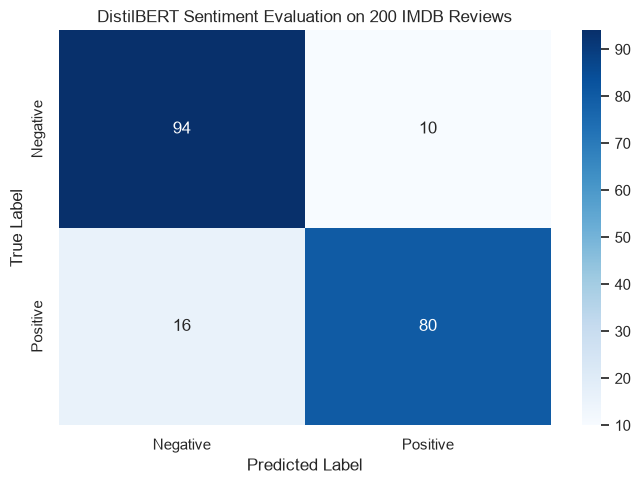

In [85]:

cm = confusion_matrix(
    true_labels,
    predicted_labels,
    labels=[0, 1]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)

plt.title("DistilBERT Sentiment Evaluation on 200 IMDB Reviews")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.savefig(
    "plots/task6_imdb_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


### IMDB Evaluation Observations

The sentiment model was evaluated on 200 IMDB test reviews using accuracy, precision, recall, F1 score, and a confusion matrix.

The model was originally fine-tuned on SST-2, while these evaluation examples come from IMDB. Differences in review style, vocabulary, length, and dataset distribution may affect the measured performance.

The results are based on a sample of 200 reviews, not the entire IMDB test set. The measured metrics should be reported as observed, without assuming that the same values will apply to every dataset.


## Task 6.2 — Compare Sentiment Performance at Different Input Lengths
Longer inputs may preserve more context, but they also increase computation. We will compare maximum input lengths of 64, 128, 256, and 512 tokens using the same 200 reviews.
## Evaluate each maximum length

In [86]:

max_lengths = [64, 128, 256, 512]

length_results = []

for max_len in max_lengths:
    start_time = time.perf_counter()

    length_predictions = sentiment_pipeline(
        review_texts,
        batch_size=16,
        truncation=True,
        max_length=max_len
    )

    elapsed_time = time.perf_counter() - start_time

    length_predicted_labels = np.array([
        1 if item["label"].upper() == "POSITIVE" else 0
        for item in length_predictions
    ])

    length_results.append({
        "Max Length": max_len,
        "Accuracy": accuracy_score(
            true_labels,
            length_predicted_labels
        ),
        "Precision": precision_score(
            true_labels,
            length_predicted_labels,
            zero_division=0
        ),
        "Recall": recall_score(
            true_labels,
            length_predicted_labels,
            zero_division=0
        ),
        "F1 Score": f1_score(
            true_labels,
            length_predicted_labels,
            zero_division=0
        ),
        "Runtime (seconds)": elapsed_time
    })

length_results_df = pd.DataFrame(length_results)

print(length_results_df.to_string(index=False))


 Max Length  Accuracy  Precision   Recall  F1 Score  Runtime (seconds)
         64     0.750   0.767442 0.687500  0.725275           8.220522
        128     0.775   0.757576 0.781250  0.769231          15.411721
        256     0.840   0.863636 0.791667  0.826087          32.104708
        512     0.870   0.888889 0.833333  0.860215          60.102146


## Plot accuracy versus maximum input length

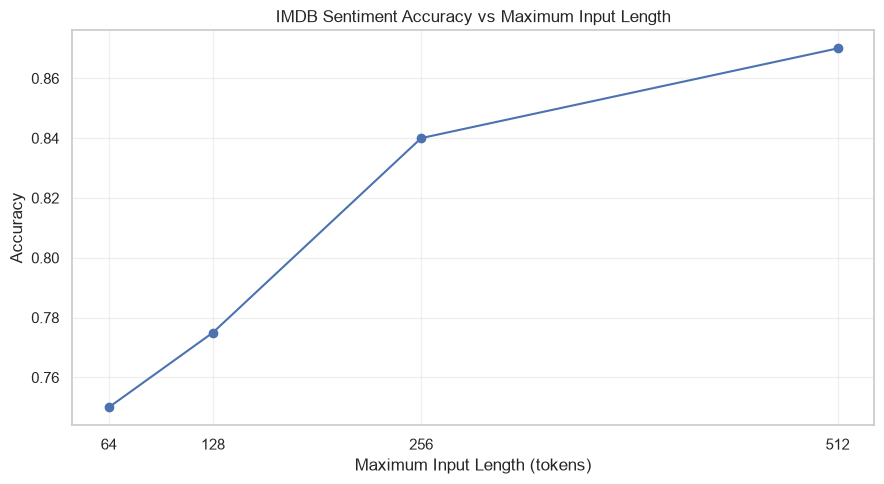

In [87]:

plt.figure(figsize=(9, 5))

plt.plot(
    length_results_df["Max Length"],
    length_results_df["Accuracy"],
    marker="o"
)

plt.xlabel("Maximum Input Length (tokens)")
plt.ylabel("Accuracy")
plt.title("IMDB Sentiment Accuracy vs Maximum Input Length")
plt.xticks(max_lengths)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(
    "plots/task6_accuracy_vs_input_length.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

## Plot runtime versus maximum input length

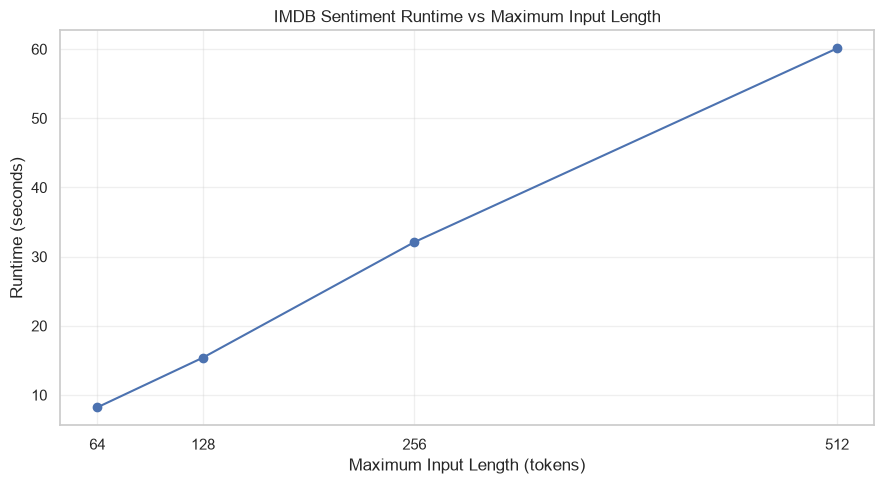

In [88]:

plt.figure(figsize=(9, 5))

plt.plot(
    length_results_df["Max Length"],
    length_results_df["Runtime (seconds)"],
    marker="o"
)

plt.xlabel("Maximum Input Length (tokens)")
plt.ylabel("Runtime (seconds)")
plt.title("IMDB Sentiment Runtime vs Maximum Input Length")
plt.xticks(max_lengths)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(
    "plots/task6_runtime_vs_input_length.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

## Count reviews longer than 512 tokens

In [89]:

sentiment_tokenizer = sentiment_pipeline.tokenizer

token_lengths = [
    len(
        sentiment_tokenizer(
            text,
            truncation=False,
            add_special_tokens=True
        )["input_ids"]
    )
    for text in review_texts
]

long_review_count = sum(
    length > 512 for length in token_lengths
)

print("Number of reviews:", len(token_lengths))
print("Reviews longer than 512 tokens:", long_review_count)
print(
    "Percentage longer than 512 tokens:",
    round(long_review_count / len(token_lengths) * 100, 2),
    "%"
)

print("\nToken length statistics:")
print(pd.Series(token_lengths).describe())


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (632 > 512). Running this sequence through the model will result in indexing errors


Number of reviews: 200
Reviews longer than 512 tokens: 18
Percentage longer than 512 tokens: 9.0 %

Token length statistics:
count     200.000000
mean      266.975000
std       189.818994
min        56.000000
25%       157.000000
50%       207.500000
75%       343.000000
max      1453.000000
dtype: float64



### Input Length Observations

The experiment compares sentiment classification at four maximum input lengths. Shorter limits reduce the amount of text processed, while longer limits can preserve additional review context.

Accuracy may improve, decline, or remain similar as the limit changes. Runtime also depends on batching, hardware, padding, and the inference implementation.

The reported runtime includes pipeline and processing overhead, so it is not a pure measurement of the neural network's forward-pass time. The longer-than-512-token count indicates how many reviews are truncated by the standard maximum used in this experiment.


## Task 6.3 — Measure Inference Time at Different Sequence Lengths
Transformer self-attention generally has a computational component that scales approximately quadratically with sequence length. We will measure the forward-pass time of DistilBERT at several input lengths.

To reduce measurement noise, we will warm up the model and repeat each measurement. Results will depend on your computer.
## Prepare the model and timing function

In [90]:

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

# Use the pretrained DistilBERT backbone.
# `model` was loaded earlier in Tasks 2-4.
model.eval()

device = next(model.parameters()).device

print("Model device:", device)
print("Maximum positions:", model.config.max_position_embeddings)


Model device: cpu
Maximum positions: 512


## Measure forward-pass latency

In [91]:

sequence_lengths = [32, 64, 128, 256, 512]
timing_results = []

base_text = (
    "Transformers use attention mechanisms to learn "
    "relationships between tokens in a sequence. "
)

for seq_len in sequence_lengths:
    encoded = tokenizer(
        base_text * 100,
        return_tensors="pt",
        truncation=True,
        max_length=seq_len,
        padding="max_length"
    )

    encoded = {
        key: value.to(device)
        for key, value in encoded.items()
    }

    # Warm-up runs.
    with torch.no_grad():
        for _ in range(3):
            _ = model(**encoded)

    # Synchronize CUDA so timings include completed GPU work.
    if device.type == "cuda":
        torch.cuda.synchronize()

    elapsed_runs = []

    with torch.no_grad():
        for _ in range(10):
            start = time.perf_counter()

            _ = model(**encoded)

            if device.type == "cuda":
                torch.cuda.synchronize()

            elapsed_runs.append(
                time.perf_counter() - start
            )

    timing_results.append({
        "Sequence Length": seq_len,
        "Mean Latency (ms)": np.mean(elapsed_runs) * 1000,
        "Std Latency (ms)": np.std(elapsed_runs) * 1000
    })

timing_df = pd.DataFrame(timing_results)

print(timing_df.to_string(index=False))


 Sequence Length  Mean Latency (ms)  Std Latency (ms)
              32           44.08006          3.084652
              64           63.22835          6.733746
             128           87.08271          6.444003
             256          167.60585          9.417450
             512          380.34640         27.549476


## Plot latency against sequence length

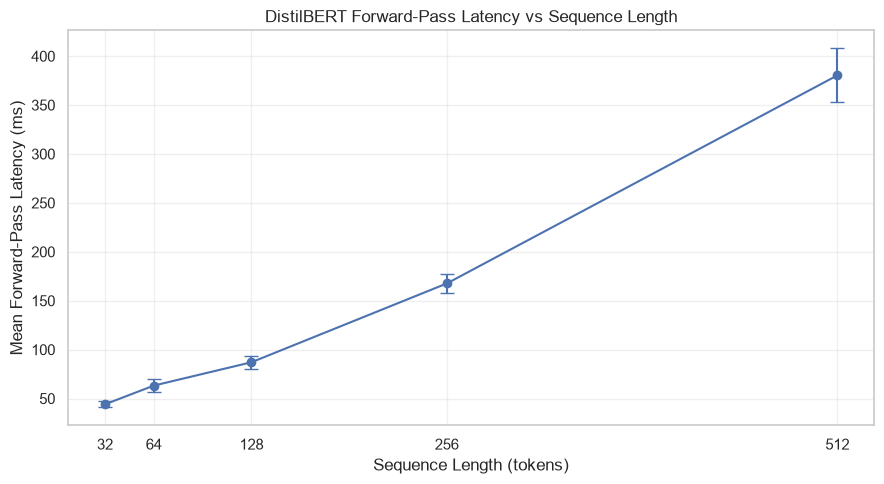

In [92]:

plt.figure(figsize=(9, 5))

plt.errorbar(
    timing_df["Sequence Length"],
    timing_df["Mean Latency (ms)"],
    yerr=timing_df["Std Latency (ms)"],
    marker="o",
    capsize=5
)

plt.xlabel("Sequence Length (tokens)")
plt.ylabel("Mean Forward-Pass Latency (ms)")
plt.title("DistilBERT Forward-Pass Latency vs Sequence Length")
plt.xticks(sequence_lengths)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(
    "plots/task6_distilbert_inference_latency.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


### Inference Latency Observations

This experiment measures the forward-pass latency of the DistilBERT backbone at different sequence lengths, using a batch size of one.

Self-attention calculates relationships between pairs of tokens, so its attention computation and memory requirements generally grow approximately quadratically with sequence length. However, the observed runtime also includes other operations, hardware effects, and implementation overhead.

The measured timings should be reported from the actual environment. Five measured sequence lengths are not enough to establish an exact mathematical scaling law for the complete model.


## Task 6.4 — Examine GPT-2's Factual Reliability
A language model can generate fluent text without guaranteeing that every statement is true. We will test GPT-2 with three factual prompts and inspect the generated continuations.
## Generate continuations for three prompts

In [93]:

factual_prompts = [
    "The capital of France is",
    "Water freezes at a temperature of",
    "The largest planet in our solar system is"
]

factual_results = []

for prompt in factual_prompts:
    input_ids = gpt2_tokenizer(
        prompt,
        return_tensors="pt"
    )["input_ids"]

    with torch.no_grad():
        output_ids = gpt2_model.generate(
            input_ids,
            max_new_tokens=30,
            do_sample=False,
            num_beams=1,
            use_cache=True,
            pad_token_id=gpt2_tokenizer.eos_token_id
        )

    generated_text = gpt2_tokenizer.decode(
        output_ids[0],
        skip_special_tokens=True
    )

    factual_results.append({
        "Prompt": prompt,
        "Generated Text": generated_text
    })

factual_df = pd.DataFrame(factual_results)

print(factual_df.to_string(index=False))


                                   Prompt                                                                                                                                                                   Generated Text
                 The capital of France is The capital of France is the capital of the French Republic, and the capital of the French Republic is the capital of the French Republic.\n\nThe French Republic is the capital
        Water freezes at a temperature of                        Water freezes at a temperature of about -40 degrees Fahrenheit (minus -20 degrees Celsius).\n\nThe ice is so thick that it can be seen from space.\n\nThe
The largest planet in our solar system is                  The largest planet in our solar system is about 1.5 billion light years away.\n\nThe planet is about 1.5 billion light years from Earth.\n\nThe planet is about


## Manually assess factual correctness

In [94]:

# Replace the example assessment values after inspecting each output.
factual_assessment = pd.DataFrame({
    "Prompt": factual_df["Prompt"],
    "Generated Text": factual_df["Generated Text"],
    "Assessment": ["Review required"] * len(factual_df),
    "Reason": ["Manually inspect the generated claim"] * len(factual_df)
})

print(factual_assessment.to_string(index=False))


                                   Prompt                                                                                                                                                                   Generated Text      Assessment                               Reason
                 The capital of France is The capital of France is the capital of the French Republic, and the capital of the French Republic is the capital of the French Republic.\n\nThe French Republic is the capital Review required Manually inspect the generated claim
        Water freezes at a temperature of                        Water freezes at a temperature of about -40 degrees Fahrenheit (minus -20 degrees Celsius).\n\nThe ice is so thick that it can be seen from space.\n\nThe Review required Manually inspect the generated claim
The largest planet in our solar system is                  The largest planet in our solar system is about 1.5 billion light years away.\n\nThe planet is about 1.5 billion light years 


### Factual Reliability Observations

GPT-2 generates text by predicting likely next tokens. Its output can be fluent and plausible, but that does not guarantee factual correctness.

The prompts in this experiment provide small examples, not a comprehensive benchmark of factual knowledge. Each generated claim should be checked against a reliable reference before it is treated as fact.

This task illustrates an important limitation of pretrained language models: next-token prediction is not the same as external fact verification.


## Task 6.5 — Build a Mini Text Toolkit
Now we will build a reusable Python function that performs three operations:
1. Sentiment analysis using DistilBERT.
2. Summarization using T5.
3. English-to-French translation of the summary using T5.
This function uses pretrained pipelines and does not fine-tune any model.

## Load or reuse the required pipelines

In [95]:
print("Sentiment model:", sentiment_pipeline.model.config._name_or_path)
print("T5 model:", t5_model.config._name_or_path)
print("T5 tokenizer:", type(t5_tokenizer).__name__)

Sentiment model: distilbert-base-uncased-finetuned-sst-2-english
T5 model: t5-small
T5 tokenizer: T5Tokenizer


## Implement text_toolkit()

In [96]:
def text_toolkit(text):

    if not isinstance(text, str) or not text.strip():
        return {
            "sentiment": "N/A",
            "sentiment_score": 0.0,
            "summary": "N/A",
            "french_translation": "N/A",
            "message": "Invalid or empty input"
        }

    # 1. Sentiment analysis
    sentiment_result = sentiment_pipeline(
        text,
        truncation=True,
        max_length=512
    )[0]

    sentiment = sentiment_result["label"]
    sentiment_score = sentiment_result["score"]

    # Get the T5 model's device
    device = next(t5_model.parameters()).device
    t5_model.eval()

    # 2. Summarization
    summary_inputs = t5_tokenizer(
        "summarize: " + text.strip(),
        return_tensors="pt",
        truncation=True,
        max_length=512
    ).to(device)

    with torch.no_grad():
        summary_ids = t5_model.generate(
            **summary_inputs,
            max_new_tokens=60,
            num_beams=4,
            do_sample=False
        )

    summary = t5_tokenizer.decode(
        summary_ids[0],
        skip_special_tokens=True
    ).strip()

    # 3. Translate summary into French
    translation_inputs = t5_tokenizer(
        "translate English to French: " + summary,
        return_tensors="pt",
        truncation=True,
        max_length=512
    ).to(device)

    with torch.no_grad():
        translation_ids = t5_model.generate(
            **translation_inputs,
            max_new_tokens=100,
            num_beams=4,
            do_sample=False
        )

    french_translation = t5_tokenizer.decode(
        translation_ids[0],
        skip_special_tokens=True
    ).strip()

    return {
        "sentiment": sentiment,
        "sentiment_score": sentiment_score,
        "summary": summary,
        "french_translation": french_translation,
        "message": "Success"
    }

## Test the toolkit on three passages

In [97]:
sample_passages = {
    "Product Review": (
        "I really enjoyed this product. It is easy to use, "
        "works well, and provides excellent value for money."
    ),

    "News-style Passage": (
        "Several cities are investing in public transportation. "
        "The projects aim to reduce traffic congestion, improve "
        "accessibility, and make commuting more efficient."
    ),

    "Technology Passage": (
        "Artificial intelligence and deep learning are changing "
        "the technology industry. These systems can analyze data, "
        "recognize images, understand language, and assist with "
        "complex tasks. Responsible development remains important."
    )
}

toolkit_results = []

for passage_type, passage in sample_passages.items():

    result = text_toolkit(passage)

    toolkit_results.append({
        "Passage Type": passage_type,
        "Sentiment": result["sentiment"],
        "Sentiment Score": result["sentiment_score"],
        "Summary": result["summary"],
        "French Translation": result["french_translation"],
        "Status": result["message"]
    })

toolkit_df = pd.DataFrame(toolkit_results)

display(toolkit_df)

,Passage Type,Sentiment,Sentiment Score,Summary,French Translation,Status
0,Product Review,POSITIVE,0.999870,"it is easy to use, works well, and provides ex...","Il est facile d'utiliser, fonctionne bien et o...",Success
1,News-style Passage,POSITIVE,0.990203,"the projects aim to reduce traffic congestion,...",Les projets visent à réduire la congestion de ...,Success
2,Technology Passage,POSITIVE,0.997501,artificial intelligence and deep learning are ...,L'intelligence artificielle et l'apprentissage...,Success


## Test empty input handling

In [98]:

empty_test_result = text_toolkit("")

print(empty_test_result)

{'sentiment': 'N/A', 'sentiment_score': 0.0, 'summary': 'N/A', 'french_translation': 'N/A', 'message': 'Invalid or empty input'}


### Mini Text Toolkit Observations

The toolkit combines pretrained Transformer pipelines into one reusable function.

- Sentiment analysis predicts whether the input is positive or negative.
- Summarization generates a shorter version of the text.
- Translation generates French text from the English summary.

The toolkit demonstrates how separate pretrained models can be combined into a simple NLP workflow. It is a demonstration rather than a production-ready application. Production use would require error handling, output validation, performance testing, privacy safeguards, and evaluation on representative data.


## Task 6.6 — Final Project Reflection


## Task 6: Final Reflection — What I Learned About Transformers

### 1. What did I understand best?

I learned how scaled dot-product attention calculates relationships between tokens, how multi-head attention uses several attention heads, and how positional information and Layer Normalization contribute to Transformer representations.

### 2. Which concept was most challenging?

Cross-attention and causal masking required careful study. Cross-attention connects decoder queries with encoder keys and values, while causal masking prevents a decoder position from accessing future tokens.

### 3. Which theory matched my practical observations?

The DistilBERT and GPT-2 attention visualizations demonstrated the difference between bidirectional encoder attention and causal decoder attention. The masking experiments also showed how future-token attention weights can be reduced to zero before softmax.

### 4. What surprised me?

Pretrained models can perform tasks such as sentiment analysis, summarization, translation, and text generation without training a new model for each experiment. However, their generated results still require evaluation.

### 5. What disadvantages did I observe?

**Limitation 1 — Computational cost:** Increasing input length affected the measured DistilBERT inference time. My measured latency at 32 tokens was [insert result] ms, compared with [insert result] ms at 512 tokens.

**Limitation 2 — Reliability:** GPT-2's factual prompts demonstrated that fluent text generation does not guarantee correctness. My observations were [describe the actual results from the three prompts].

### 6. What real-world application interests me?

A useful application is a customer feedback analysis system that classifies sentiment, summarizes customer reviews, and translates summaries into another language. Such a system could help analysts review large volumes of feedback more efficiently.

### 7. Final conclusion

This project helped me connect Transformer theory with practical implementation. I studied attention, positional encoding, Layer Normalization, encoder architecture, causal masking, cross-attention, decoding strategies, caching, and evaluation.

I also learned that model outputs must be evaluated for accuracy, reliability, latency, and suitability for the intended task. Pretrained models provide powerful capabilities, but they do not eliminate the need for validation and human oversight.


## Task 6.7 — Notebook Quality and Submission Checklist

## Record the package versions

In [99]:

import sys
import torch
import transformers
import datasets
import numpy
import pandas
import sklearn
import matplotlib
import seaborn

print("Python:", sys.version)
print("torch==", torch.__version__)
print("transformers==", transformers.__version__)
print("datasets==", datasets.__version__)
print("numpy==", numpy.__version__)
print("pandas==", pandas.__version__)
print("scikit-learn==", sklearn.__version__)
print("matplotlib==", matplotlib.__version__)
print("seaborn==", seaborn.__version__)


Python: 3.11.4 (tags/v3.11.4:d2340ef, Jun  7 2023, 05:45:37) [MSC v.1934 64 bit (AMD64)]
torch== 2.14.0+cpu
transformers== 5.20.2
datasets== 5.1.0
numpy== 2.4.6
pandas== 3.0.6
scikit-learn== 1.9.1
matplotlib== 3.11.2
seaborn== 0.13.2
